# Freight Rate Prediction

Predict `posted_rate` (USD) for truckload freight loads.

| Data | Rows | Dates | Use |
|---|---|---|---|
| `train-test.csv` | 48,000 | 2025-01-01 → 2025-10-31 | Labelled development data |
| `validation.csv` | 12,000 | 2025-11-01 → 2025-12-31 | Final predictions (no labels) |
| `december-chart-inputs.csv` | 31 | 2025-12-01 → 2025-12-31 | One fixed lane, only date varies |

**Notebook sections**
1. Exploratory data analysis
2. Data cleaning
3. Feature engineering
4. Validation strategy & train/test split
5. Models
6. Final predictions & scoring

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train-test.csv", parse_dates=["date"])
valid = pd.read_csv(DATA_DIR / "validation.csv", parse_dates=["date"])
december = pd.read_csv(DATA_DIR / "december-chart-inputs.csv", parse_dates=["date"])

for name, df in [("train", train), ("validation", valid), ("december", december)]:
    print(f"{name:<11} {df.shape}  {df['date'].min().date()} → {df['date'].max().date()}")

train       (48000, 14)  2025-01-01 → 2025-10-31
validation  (12000, 13)  2025-11-01 → 2025-12-31
december    (31, 7)  2025-12-01 → 2025-12-31


In [2]:
def haversine_miles(lat1, lon1, lat2, lon2):
    """Great-circle distance in miles."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(h))

for df in (train, valid):
    df["straight_line_mi"] = haversine_miles(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
    df["month"] = df["date"].dt.month
train["rate_per_mile"] = train["posted_rate"] / train["distance"]

train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,straight_line_mi,month,rate_per_mile
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,219.808768,1,2.352935
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,220.525617,1,2.424135
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,826.919847,1,1.862513
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,840.540749,1,1.892770
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,434.163187,1,2.547112


---
# 1. Exploratory data analysis

## 1.1 Column summary, missing values, duplicates

In [3]:
train.drop(columns=["straight_line_mi", "month", "rate_per_mile"]).describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
load_id,48000,48000,TR-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup,48000,64,Oklahoma City,1242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery,48000,64,Lexington,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_lat,48000.0,NaN,NaN,NaN,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,NaN,NaN,NaN,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,NaN,NaN,NaN,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,NaN,NaN,NaN,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,NaN,NaN,NaN,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
equipment,48000,3,Dry Van,27202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,47700.0,NaN,NaN,NaN,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062


In [4]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "valid_missing": valid.isna().sum(),
}).query("train_missing > 0 or valid_missing > 0")
missing["train_%"] = (missing.train_missing / len(train) * 100).round(2)
missing["valid_%"] = (missing.valid_missing / len(valid) * 100).round(2)
print(missing.drop(index="rate_per_mile", errors="ignore"))

feature_cols = ["pickup", "delivery", "distance", "equipment", "weight", "date", "market_index", "quote_signal"]
print("\nduplicate load_id     train:", train.load_id.duplicated().sum(), " valid:", valid.load_id.duplicated().sum())
print("duplicate feature rows train:", train.duplicated(feature_cols).sum(), " valid:", valid.duplicated(feature_cols).sum())

              train_missing  valid_missing  train_%  valid_%
market_index            374          249.0     0.78     2.08
weight                  300          165.0     0.62     1.38

duplicate load_id     train: 0  valid: 0
duplicate feature rows train: 0  valid: 0


## 1.2 Target: `posted_rate`

Raw rates mostly reflect trip length, so the more useful view is **rate per mile**.

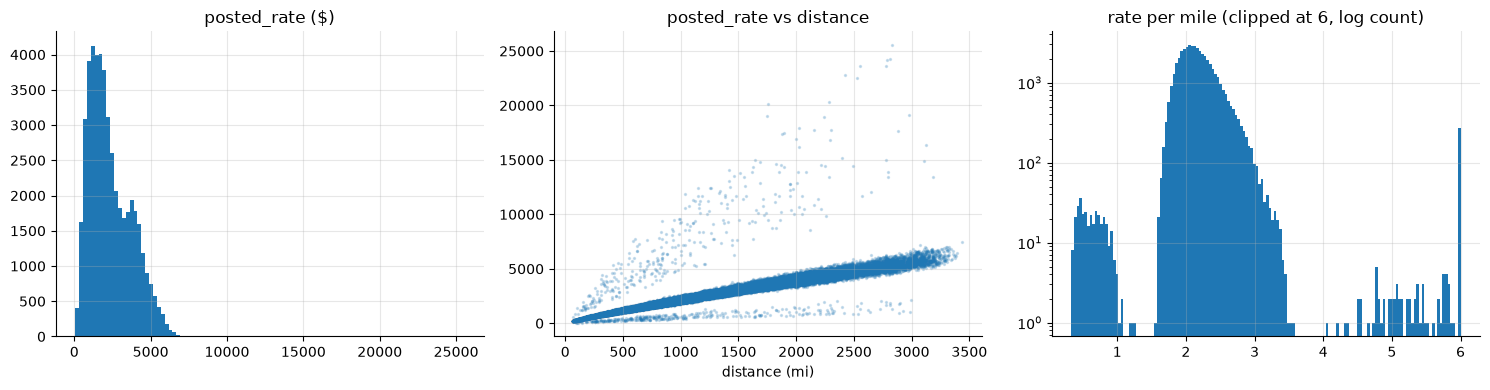

count    48000.000
mean         2.215
std          0.584
min          0.334
0.1%         0.437
1%           1.674
5%           1.808
50%          2.145
95%          2.736
99%          3.177
99.9%       10.069
max         14.125
Name: rate_per_mile, dtype: float64

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(train.posted_rate, bins=100); ax[0].set_title("posted_rate ($)")
ax[1].scatter(train.distance, train.posted_rate, s=2, alpha=0.2); ax[1].set_title("posted_rate vs distance")
ax[1].set_xlabel("distance (mi)")
ax[2].hist(train.rate_per_mile.clip(upper=6), bins=150); ax[2].set_yscale("log")
ax[2].set_title("rate per mile (clipped at 6, log count)")
plt.tight_layout(); plt.show()

train.rate_per_mile.describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).round(3)

The rate-vs-distance scatter shows a dense main band, plus a sparse band far **above** it and another **below** it.
Those look like data-entry errors rather than real prices. To measure them, compare each load's rate per mile
with the median for loads that have the same equipment and similar distance (distance decile).

0.001    0.202
0.003    0.254
0.005    0.345
0.010    0.867
0.500    1.000
0.990    1.165
0.995    2.983
0.997    3.515
0.999    4.611

rate ≥2.5× expected: 299 rows   (ratio range 2.50–5.22)
rate ≤0.4× expected: 312 rows   (ratio range 0.17–0.40)
total suspect: 611 rows = 1.27% of training data


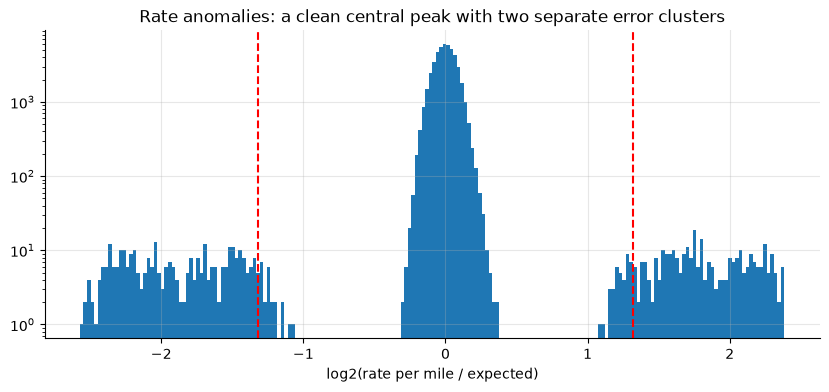

,pickup,delivery,distance,equipment,posted_rate,rate_per_mile,rate_ratio
45059,Raleigh,Columbia,420.9,Reefer,183.77,0.436612,0.168201
2511,Buffalo,San Antonio,1644.3,Flatbed,596.04,0.362489,0.172689
508,Las Vegas,Grand Rapids,1976.4,Flatbed,699.41,0.353881,0.173428
28012,Montgomery,Houston,604.3,Reefer,7773.37,12.863429,5.197445
27969,Buffalo,Boston,589.9,Reefer,7597.52,12.879335,5.203872
40096,Baltimore,Oklahoma City,1760.3,Reefer,20132.37,11.436897,5.224877


In [6]:
train["dist_decile"] = pd.qcut(train.distance, 10)
expected_rpm = train.groupby(["equipment", "dist_decile"], observed=True).rate_per_mile.transform("median")
train["rate_ratio"] = train.rate_per_mile / expected_rpm

print(train.rate_ratio.quantile([.001, .003, .005, .01, .5, .99, .995, .997, .999]).round(3).to_string())
high = train.rate_ratio > 2.5
low = train.rate_ratio < 0.4
print(f"\nrate ≥2.5× expected: {high.sum()} rows   (ratio range {train.rate_ratio[high].min():.2f}–{train.rate_ratio[high].max():.2f})")
print(f"rate ≤0.4× expected: {low.sum()} rows   (ratio range {train.rate_ratio[low].min():.2f}–{train.rate_ratio[low].max():.2f})")
print(f"total suspect: {(high | low).sum()} rows = {(high | low).mean():.2%} of training data")

fig, ax = plt.subplots()
ax.hist(np.log2(train.rate_ratio), bins=200); ax.set_yscale("log")
ax.axvline(np.log2(2.5), color="red", ls="--"); ax.axvline(np.log2(0.4), color="red", ls="--")
ax.set_xlabel("log2(rate per mile / expected)"); ax.set_title("Rate anomalies: a clean central peak with two separate error clusters")
plt.show()

train.loc[high | low, ["pickup", "delivery", "distance", "equipment", "posted_rate", "rate_per_mile", "rate_ratio"]].sort_values("rate_ratio").iloc[[0, 1, 2, -3, -2, -1]]

## 1.3 `weight`

negative: 292 | missing: 300 | == 47,500: 1191 | == -47,500: 13 | == 5,000: 31
negative weights look like normal weights with a flipped sign:
count      292.0
mean     31724.0
std       8263.0
min       5000.0
25%      25928.0
50%      31822.0
75%      37284.0
max      47500.0
valid negative: 145 | valid == 47,500: 297


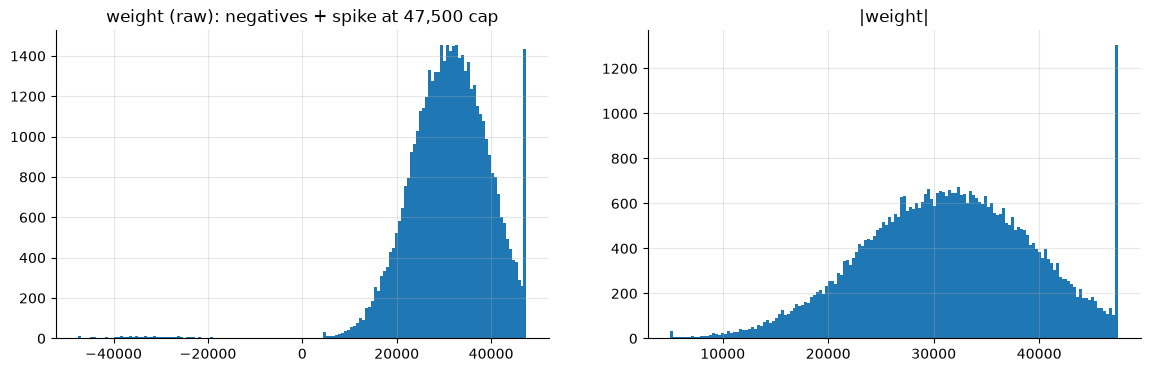

,count,median
weight,,
"(0, 10000]",200,2.023
"(10000, 20000]",3516,2.061
"(20000, 30000]",16454,2.101
"(30000, 40000]",19902,2.175
"(40000, 47499]",5830,2.216
"(47499, 47500]",1190,2.198


In [7]:
w = train.weight
print("negative:", (w < 0).sum(), "| missing:", w.isna().sum(),
      "| == 47,500:", (w == 47_500).sum(), "| == -47,500:", (w == -47_500).sum(), "| == 5,000:", (w == 5_000).sum())
print("negative weights look like normal weights with a flipped sign:")
print((-w[w < 0]).describe().round(0).to_string())
print("valid negative:", (valid.weight < 0).sum(), "| valid == 47,500:", (valid.weight == 47_500).sum())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(w.dropna(), bins=150); ax[0].set_title("weight (raw): negatives + spike at 47,500 cap")
ax[1].hist(w.abs().dropna(), bins=150); ax[1].set_title("|weight|")
plt.show()

clean = train[~(high | low)]
wb = pd.cut(clean.weight.abs(), [0, 10_000, 20_000, 30_000, 40_000, 47_499, 47_500])
clean.groupby(wb, observed=True).rate_per_mile.agg(["count", "median"]).round(3)

## 1.4 `distance`, coordinates and cities

In [8]:
ratio = train.distance / train.straight_line_mi
print("distance / straight-line distance:")
print(ratio.describe(percentiles=[.01, .05, .5, .95, .99]).round(3).to_string())
print("\nrows at the 70-mile minimum: train", (train.distance == 70).sum(), "| valid", (valid.distance == 70).sum())

# Each city always has the same coordinates…
all_rows = pd.concat([train, valid])
print("cities with >1 coordinate pair:",
      (all_rows.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max(axis=1) > 1).sum())
# …but the coordinates are not real-world geography
la_phx = train[(train.pickup == "Los Angeles") & (train.delivery == "Phoenix")].iloc[0]
print(f"e.g. Los Angeles → Phoenix: straight line {la_phx.straight_line_mi:.0f} mi, distance column {la_phx.distance:.0f} mi (real road ≈ 370 mi)")

lane_std = train.groupby(["pickup", "delivery"]).distance.std()
print(f"\nsame lane, different distance: median std {lane_std.median():.1f} mi → distance varies by load")

distance / straight-line distance:
count    48000.000
mean         1.195
std          0.144
min          1.058
1%           1.130
5%           1.143
50%          1.182
95%          1.273
99%          1.404
max          9.635

rows at the 70-mile minimum: train 48 | valid 21
cities with >1 coordinate pair: 0
e.g. Los Angeles → Phoenix: straight line 52 mi, distance column 84 mi (real road ≈ 370 mi)

same lane, different distance: median std 15.9 mi → distance varies by load


In [9]:
train_cities = set(train.pickup) | set(train.delivery)
valid_cities = set(valid.pickup) | set(valid.delivery)
unseen = sorted(valid_cities - train_cities)
touch = valid.pickup.isin(unseen) | valid.delivery.isin(unseen)
print(f"cities in train: {len(train_cities)}, in validation: {len(valid_cities)}")
print(f"cities only in validation: {unseen}")
print(f"validation rows touching an unseen city: {touch.sum():,} ({touch.mean():.1%})")
print(f"train lanes: {train.groupby(['pickup','delivery']).ngroups:,}")

cities in train: 64, in validation: 72
cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation rows touching an unseen city: 1,447 (12.1%)
train lanes: 4,014


## 1.5 `equipment`

In [10]:
clean.groupby("equipment").agg(loads=("rate_per_mile", "size"),
                               median_rpm=("rate_per_mile", "median"),
                               median_rate=("posted_rate", "median")).round(2)

,loads,median_rpm,median_rate
equipment,,,
Dry Van,26870,2.05,1953.22
Flatbed,8637,2.22,2078.60
Reefer,11882,2.31,2202.01


## 1.6 Rate per mile vs distance

Short loads cost much more per mile, because fixed costs (loading, waiting, empty miles) are spread over fewer miles.

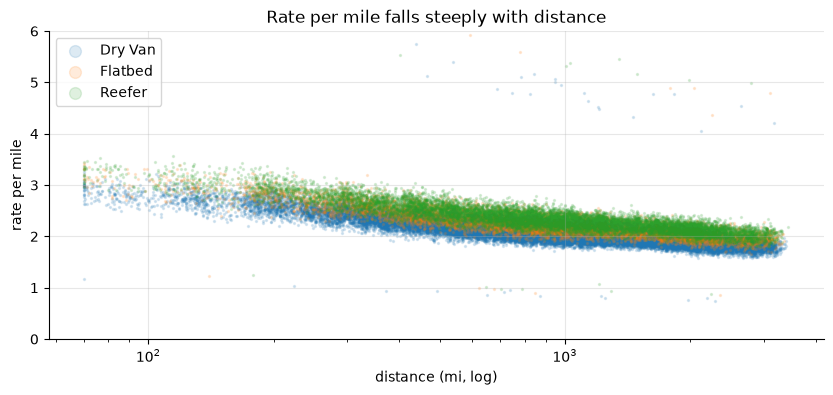

corr(log rate/mile, log distance): -0.764


In [11]:
fig, ax = plt.subplots()
for eq, g in clean.groupby("equipment"):
    ax.scatter(g.distance, g.rate_per_mile, s=2, alpha=0.15, label=eq)
ax.set_xscale("log"); ax.set_ylim(0, 6); ax.set_xlabel("distance (mi, log)"); ax.set_ylabel("rate per mile")
ax.legend(markerscale=6); ax.set_title("Rate per mile falls steeply with distance")
plt.show()
print("corr(log rate/mile, log distance):", np.corrcoef(np.log(clean.rate_per_mile), np.log(clean.distance))[0, 1].round(3))

## 1.7 Time, `market_index` and `quote_signal`

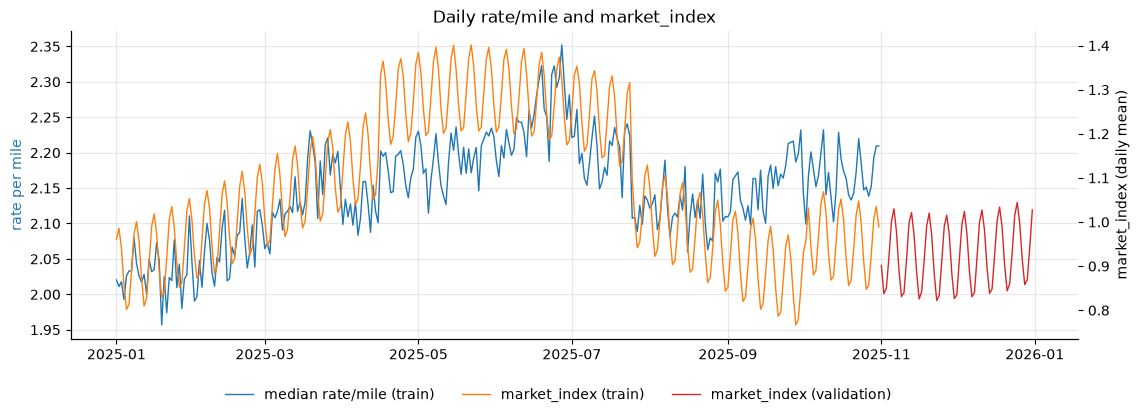

,loads,median_rpm,market_index,quote_signal
month,,,,
1,4845,2.029,0.927,2.068
2,4285,2.062,0.996,2.096
3,4974,2.140,1.073,2.179
4,4759,2.147,1.207,1.965
5,4855,2.191,1.301,1.913
6,4726,2.246,1.280,2.297
7,4855,2.187,1.201,1.923
8,4698,2.121,0.981,2.053
9,4612,2.159,0.893,2.200


In [12]:
daily = clean.groupby("date").agg(rpm=("rate_per_mile", "median"), mi=("market_index", "mean"))
vdaily = valid.groupby("date").agg(mi=("market_index", "mean"))

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.plot(daily.index, daily.rpm, color="C0", lw=1, label="median rate/mile (train)")
ax1.set_ylabel("rate per mile", color="C0")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily.mi, color="C1", lw=1, label="market_index (train)")
ax2.plot(vdaily.index, vdaily.mi, color="C3", lw=1, label="market_index (validation)")
ax2.set_ylabel("market_index (daily mean)"); ax2.grid(False)
fig.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08), frameon=False)
ax1.set_title("Daily rate/mile and market_index")
plt.show()

monthly = pd.concat([
    clean.groupby("month").agg(loads=("rate_per_mile", "size"), median_rpm=("rate_per_mile", "median"),
                               market_index=("market_index", "mean"), quote_signal=("quote_signal", "mean")),
    valid.groupby("month").agg(loads=("load_id", "size"), market_index=("market_index", "mean"),
                               quote_signal=("quote_signal", "mean")),
])
monthly.round(3)

In [13]:
for col in ["market_index", "quote_signal"]:
    within = train.groupby("date")[col].std().mean()
    across = train.groupby("date")[col].mean().std()
    print(f"{col:<13} spread within a day {within:.3f} | spread of daily means {across:.3f}")

dow = clean.groupby(clean.date.dt.day_name()).rate_per_mile.median()
print("\nmedian rate/mile by weekday:", dow.round(3).to_dict())

c = clean.assign(log_rpm=np.log(clean.rate_per_mile), log_distance=np.log(clean.distance), weight=clean.weight.abs())
c[["log_rpm", "log_distance", "weight", "market_index", "quote_signal"]].corr()["log_rpm"].round(3)

market_index  spread within a day 0.025 | spread of daily means 0.167
quote_signal  spread within a day 0.261 | spread of daily means 0.129

median rate/mile by weekday: {'Friday': 2.158, 'Monday': 2.127, 'Saturday': 2.132, 'Sunday': 2.128, 'Thursday': 2.171, 'Tuesday': 2.139, 'Wednesday': 2.162}


log_rpm         1.000
log_distance   -0.764
weight          0.189
market_index    0.176
quote_signal    0.101
Name: log_rpm, dtype: float64

### Does `market_index` keep predicting rates over time?

`market_index` swings in a weekly cycle. Below: (a) that cycle by weekday, and (b) how closely the daily average
rate (adjusted for distance and equipment) follows `market_index` in each part of the year.

In [14]:
weekday = pd.DataFrame({
    "market_index_train": train.groupby(train.date.dt.dayofweek).market_index.mean(),
    "market_index_valid": valid.groupby(valid.date.dt.dayofweek).market_index.mean(),
    "median_rate_ratio": clean.groupby(clean.date.dt.dayofweek).rate_ratio.median(),
})
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(weekday.round(3), "\n")

c = clean.assign(log_ratio=np.log(clean.rate_ratio))
for label, mask in [("Jan–Jul", c.month <= 7), ("Aug–Oct", c.month >= 8)]:
    d = c[mask].groupby("date").agg(log_ratio=("log_ratio", "mean"), mi=("market_index", "mean"))
    print(f"{label}: corr(daily adjusted rate, daily market_index) = {d.log_ratio.corr(d.mi):.2f}")

     market_index_train  market_index_valid  median_rate_ratio
Mon               1.000               0.846              0.992
Tue               1.075               0.921              0.998
Wed               1.153               1.002              1.008
Thu               1.179               1.027              1.011
Fri               1.134               0.980              1.007
Sat               1.047               0.895              0.995
Sun               0.989               0.835              0.989 

Jan–Jul: corr(daily adjusted rate, daily market_index) = 0.90
Aug–Oct: corr(daily adjusted rate, daily market_index) = 0.24


## 1.8 December chart lane

The December file has only `pickup, delivery, distance, equipment, weight, date`. It does **not** include
coordinates, `market_index` or `quote_signal`, so any model that uses them needs a way to fill them in for this file.

In [15]:
print("december columns:", list(december.columns))
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne")]
print(f"Lexington → Fort Wayne in training: {len(lane)} loads, distance {lane.distance.min()}–{lane.distance.max()} mi")
print("equipment:", lane.equipment.value_counts().to_dict())
print("December dates present in validation.csv:",
      valid.date.dt.strftime('%Y-%m').eq('2025-12').sum(), "rows on", valid[valid.month == 12].date.nunique(), "days")
lane[["date", "distance", "equipment", "weight", "market_index", "quote_signal", "posted_rate"]].sort_values("date").tail(10)

december columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
Lexington → Fort Wayne in training: 32 loads, distance 346.3–384.5 mi
equipment: {'Dry Van': 21, 'Reefer': 8, 'Flatbed': 3}
December dates present in validation.csv: 6164 rows on 31 days


,date,distance,equipment,weight,market_index,quote_signal,posted_rate
35557,2025-08-13,360.8,Dry Van,22007.0,1.06957,1.61911,796.71
36972,2025-08-22,358.6,Reefer,30227.0,1.04508,2.52477,946.18
37239,2025-08-24,384.5,Reefer,24375.0,0.87043,1.55362,935.47
37870,2025-08-27,346.3,Reefer,38755.0,1.05429,1.80401,910.55
40765,2025-09-15,350.9,Dry Van,22972.0,0.81021,2.24980,778.24
41842,2025-09-22,369.8,Reefer,26905.0,0.80501,2.60044,959.92
43271,2025-10-01,371.4,Dry Van,26829.0,0.90458,1.87336,841.42
43376,2025-10-02,354.1,Reefer,27073.0,0.96814,1.58181,901.41
47076,2025-10-26,363.0,Dry Van,17917.0,0.83786,1.95187,796.48
47722,2025-10-30,370.3,Dry Van,26358.0,1.01336,1.82144,864.61


## 1.9 EDA findings

**Data-quality issues**

| # | Issue | Size | Planned handling |
|---|---|---|---|
| 1 | `posted_rate` errors: rate ≈ 2.5–5× or ≈ 0.17–0.4× what similar loads cost | ~611 rows (~1.3%) | Remove from training (they'd distort the fit and the metric) |
| 2 | Negative `weight`, values that look like normal weights with the sign flipped | 292 train / 145 valid | Take the absolute value |
| 3 | `weight` capped at 47,500 lb (and 5,000 lb floor) | ~2.5% of rows at the cap | Keep the value, add an "at cap" flag |
| 4 | Missing `weight` | 300 train / 165 valid | Impute (median by equipment) + missing flag |
| 5 | Missing `market_index` | 374 train / 249 valid | Impute from the same day's mean (it is mostly a daily market level) |
| 6 | Coordinates don't match real geography, but each city's coordinates are consistent | all rows | Trust `distance`; use coordinates only as location features |
| 7 | 8 cities appear only in validation (Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego) | 1,447 valid rows (12%) | Prefer coordinate features over city IDs; any city encoding needs a fallback |
| 8 | December chart file lacks coordinates, `market_index`, `quote_signal` | 31 rows | Coordinates from the city lookup; `market_index` from validation's daily mean for that date; `quote_signal` turns out not to be needed (section 2.8) |

**Patterns that matter for the model**
- Rate is driven mainly by **distance**; rate per mile falls steeply with distance.
- **Equipment**: Reefer > Flatbed > Dry Van per mile.
- **`market_index`** is mostly a market-wide daily level. It peaks in May (~1.30), and Nov–Dec (~0.92–0.94)
  is close to January and September, so validation sits inside the training range.
- **`market_index` has a weekly cycle** (high Wed/Thu, low Sun/Mon) that rates barely show.
- **Its link to rates weakens over time**: daily correlation ≈ 0.90 in Jan–Jul but ≈ 0.24 in Aug–Oct. Rates held up
  in the autumn while the index fell. Nov–Dec index values are low, so a model leaning on `market_index` risks
  under-predicting. A time-based split will show whether that happens; a random split would hide it.
- **`quote_signal`** varies mostly between loads, not between days, and correlates only weakly with rate overall.
  Section 2.8 shows why that is misleading: it is a disguised copy of the target in most training months.
- Weekday effect is small.
- The target period (Nov–Dec) comes **after** all training data, so validation should be time-based.

---
# 2. Data cleaning

For every issue: **(1)** state the problem, **(2)** look at the distribution around it, **(3)** try the standard fixes
and score them wherever a score is possible, **(4)** choose based on the evidence.

Ground rules
- A value is **fixed** when the true value can be recovered, **flagged** when it is real but limited (e.g. capped),
  **filled in** when missing, and **dropped** only when it is wrong and unrecoverable.
- Fill-in methods are **learned on training data only** and applied unchanged to validation and December (no leakage).
- Rows are removed **only from training**. Validation must keep all 12,000 loads.

In [16]:
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (enables IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler

SEED = 42
raw_train = pd.read_csv(DATA_DIR / "train-test.csv", parse_dates=["date"])
raw_valid = pd.read_csv(DATA_DIR / "validation.csv", parse_dates=["date"])
raw_dec = pd.read_csv(DATA_DIR / "december-chart-inputs.csv", parse_dates=["date"])
EQUIPMENT = sorted(raw_train.equipment.unique())

def numeric_frame(df):
    """All load features as numbers (used by the detectors and imputers below)."""
    return pd.DataFrame({
        "log_distance": np.log(df.distance),
        "equipment": pd.Categorical(df.equipment, categories=EQUIPMENT).codes,
        "weight": df.weight, "market_index": df.market_index, "quote_signal": df.quote_signal,
        "day_of_year": df.date.dt.dayofyear, "day_of_week": df.date.dt.dayofweek,
        "pickup_lat": df.pickup_lat, "pickup_lon": df.pickup_lon,
        "delivery_lat": df.delivery_lat, "delivery_lon": df.delivery_lon,
    }, index=df.index)

## 2.1 Text values, dates, duplicates

In [17]:
for col in ["pickup", "delivery", "equipment"]:
    s = pd.concat([raw_train[col], raw_valid[col], raw_dec[col]])
    print(f"{col:<10} stray whitespace: {(s != s.str.strip()).sum()}   case variants: {s.nunique() - s.str.strip().str.lower().nunique()}")
print("equipment values:", EQUIPMENT)
print("unparseable dates:", raw_train.date.isna().sum() + raw_valid.date.isna().sum() + raw_dec.date.isna().sum())
print("duplicate load_ids:", raw_train.load_id.duplicated().sum() + raw_valid.load_id.duplicated().sum())

pickup     stray whitespace: 0   case variants: 0
delivery   stray whitespace: 0   case variants: 0
equipment  stray whitespace: 0   case variants: 0
equipment values: ['Dry Van', 'Flatbed', 'Reefer']
unparseable dates: 0
duplicate load_ids: 0


Nothing to fix: categories are consistent, dates parse, no duplicates.

## 2.2 Negative `weight`

negative weights: train 292, validation 145
KS test, |negative| vs positive weights: statistic 0.041, p = 0.70
median rate ratio of negative-weight loads: 1.002  (all loads 1.000)


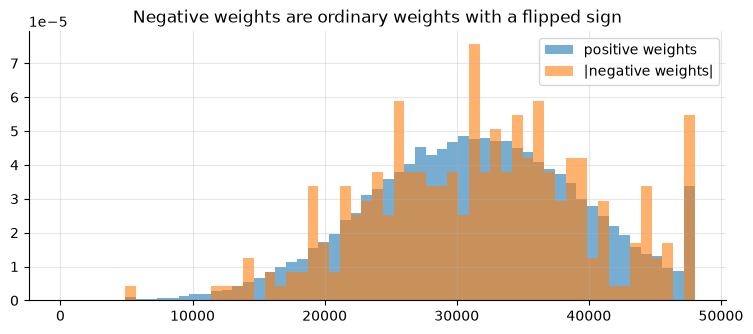

In [18]:
w = raw_train.weight
neg, pos = -w[w < 0], w[w > 0]
ks = stats.ks_2samp(neg, pos)
print(f"negative weights: train {(w < 0).sum()}, validation {(raw_valid.weight < 0).sum()}")
print(f"KS test, |negative| vs positive weights: statistic {ks.statistic:.3f}, p = {ks.pvalue:.2f}")
print(f"median rate ratio of negative-weight loads: {train.rate_ratio[w < 0].median():.3f}  (all loads {train.rate_ratio.median():.3f})")

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(0, 48_000, 60)
ax.hist(pos, bins=bins, density=True, alpha=0.6, label="positive weights")
ax.hist(neg, bins=bins, density=True, alpha=0.6, label="|negative weights|")
ax.legend(); ax.set_title("Negative weights are ordinary weights with a flipped sign"); plt.show()

**Options:** drop the rows · treat as missing and fill in · take the absolute value.

**Decision: absolute value.** The magnitudes follow the same distribution as real weights (the KS test finds no
difference) and those loads have normal rates, so the true value is recoverable. Dropping or filling in would throw
away good information.

## 2.3 `weight` cap and floor

In [19]:
wa = raw_train.weight.abs()
print("at the 47,500 cap:", (wa == 47_500).sum(), "| at the 5,000 floor:", (wa == 5_000).sum(),
      "| min:", wa.min(), "| max:", wa.max())
band = pd.cut(wa, [0, 5_000, 20_000, 40_000, 47_499, 47_500],
              labels=["= 5,000 (floor)", "5–20k", "20–40k", "40–47.5k", "= 47,500 (cap)"])
ok = train.rate_ratio.between(0.4, 2.5)
pd.DataFrame({"loads": band.value_counts().sort_index(),
              "median rate ratio": train.rate_ratio[ok].groupby(band[ok], observed=True).median().round(3)})

at the 47,500 cap: 1204 | at the 5,000 floor: 32 | min: 5000.0 | max: 47500.0


,loads,median rate ratio
weight,,
"= 5,000 (floor)",32,0.942
5–20k,3742,0.959
20–40k,36812,0.998
40–47.5k,5910,1.032
"= 47,500 (cap)",1204,1.032


The spike at 47,500 lb means heavier loads were recorded as 47,500 (the value is **capped**, not wrong).
Those loads price like other heavy loads.

**Options:** drop · set to missing and fill in · keep.
**Decision: keep the value and add `weight_at_cap` / `weight_at_floor` flags**, so a model can learn any extra effect.

## 2.4 Wrong `posted_rate` values

A useful detector has to judge each rate **against what that load should cost**. $600 is normal for a 250-mile trip
and far too low for a 1,600-mile one. So the main candidate models log(rate) from the load's features, using:
- **out-of-fold predictions**: each row is predicted by a model that never saw it, and
- an **absolute-error loss**, so the bad rows barely pull the fit.

Each row's residual is log(actual rate / expected rate). `quote_signal` is left out of the detector (section 2.8
shows it is a disguised copy of the target).

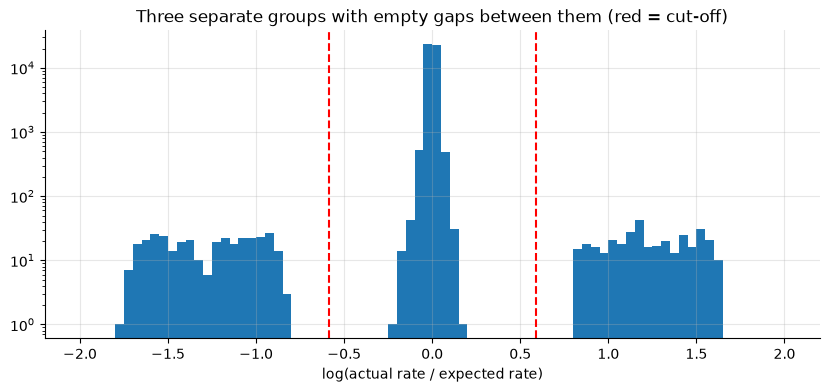

residual -2.0 … -0.7:    337 rows
residual -0.7 … -0.3:      0 rows
residual -0.3 … +0.3:  47323 rows
residual +0.3 … +0.7:      0 rows
residual +0.7 … +2.0:    340 rows


In [20]:
detector = HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, categorical_features=[1], random_state=SEED)
X_det = numeric_frame(raw_train.assign(weight=raw_train.weight.abs())).drop(columns="quote_signal")
expected_log_rate = cross_val_predict(detector, X_det, np.log(raw_train.posted_rate),
                                      cv=KFold(5, shuffle=True, random_state=SEED))
residual = pd.Series(np.log(raw_train.posted_rate) - expected_log_rate, index=raw_train.index)

fig, ax = plt.subplots()
ax.hist(residual, bins=np.arange(-2, 2.01, 0.05)); ax.set_yscale("log")
for x in (-np.log(1.8), np.log(1.8)):
    ax.axvline(x, color="red", ls="--")
ax.set_xlabel("log(actual rate / expected rate)")
ax.set_title("Three separate groups with empty gaps between them (red = cut-off)")
plt.show()

for lo, hi in [(-2, -0.7), (-0.7, -0.3), (-0.3, 0.3), (0.3, 0.7), (0.7, 2)]:
    print(f"residual {lo:+.1f} … {hi:+.1f}: {((residual > lo) & (residual <= hi)).sum():>6} rows")

In [21]:
IS_RATE_ERROR = residual.abs() > np.log(1.8)    # any cut inside the empty gap selects exactly the same rows
truth = IS_RATE_ERROR

def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

rpm = raw_train.posted_rate / raw_train.distance
group_ratio = rpm / rpm.groupby([raw_train.equipment, pd.qcut(raw_train.distance, 10)], observed=True).transform("median")
robust_sd = 1.4826 * (residual - residual.median()).abs().median()
iso = IsolationForest(contamination=float(truth.mean()), random_state=SEED).fit_predict(
    np.c_[np.log(raw_train.distance), np.log(raw_train.posted_rate)])

candidates = {
    "IQR on posted_rate": iqr_flag(raw_train.posted_rate),
    "z-score > 3 on posted_rate": pd.Series(np.abs(stats.zscore(raw_train.posted_rate)) > 3, index=raw_train.index),
    "IQR on rate per mile": iqr_flag(rpm),
    "Isolation Forest (log distance, log rate)": pd.Series(iso == -1, index=raw_train.index),
    "ratio to equipment × distance-decile median (EDA rule)": (group_ratio > 2.5) | (group_ratio < 0.4),
    "model residual, robust z > 5": (residual - residual.median()).abs() / robust_sd > 5,
    "model residual, cut inside the gap": truth,
}
pd.DataFrame({name: {"flagged": int(f.sum()),
                     "errors caught": f"{int((f & truth).sum())} / {int(truth.sum())}",
                     "normal loads wrongly flagged": int((f & ~truth).sum())}
              for name, f in candidates.items()}).T

,flagged,errors caught,normal loads wrongly flagged
IQR on posted_rate,260,177 / 677,83
z-score > 3 on posted_rate,183,169 / 677,14
IQR on rate per mile,1634,677 / 677,957
"Isolation Forest (log distance, log rate)",677,140 / 677,537
ratio to equipment × distance-decile median (EDA rule),611,611 / 677,0
"model residual, robust z > 5",756,677 / 677,79
"model residual, cut inside the gap",677,677 / 677,0


In [22]:
multiplier = np.exp(residual[truth])
hi_bins, lo_bins = [2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5], [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
print("too high, actual/expected:", dict(zip([f"{a}–{b}×" for a, b in zip(hi_bins, hi_bins[1:])],
                                              np.histogram(multiplier[multiplier > 1], bins=hi_bins)[0])))
print("too low,  actual/expected:", dict(zip([f"{a}–{b}×" for a, b in zip(lo_bins, lo_bins[1:])],
                                              np.histogram(multiplier[multiplier < 1], bins=lo_bins)[0])))
print(f"\nrows to drop: {truth.sum()} ({truth.mean():.2%})")
print("by equipment:", raw_train.equipment[truth].value_counts().to_dict())
print("by month:    ", raw_train.date[truth].dt.month.value_counts().sort_index().to_dict())

too high, actual/expected: {'2–2.5×': np.int64(36), '2.5–3×': np.int64(65), '3–3.5×': np.int64(86), '3.5–4×': np.int64(49), '4–4.5×': np.int64(47), '4.5–5×': np.int64(51), '5–5.5×': np.int64(6)}
too low,  actual/expected: {'0.15–0.2×': np.int64(40), '0.2–0.25×': np.int64(97), '0.25–0.3×': np.int64(47), '0.3–0.35×': np.int64(64), '0.35–0.4×': np.int64(61), '0.4–0.5×': np.int64(28)}

rows to drop: 677 (1.41%)
by equipment: {'Dry Van': 368, 'Reefer': 182, 'Flatbed': 127}
by month:     {1: 81, 2: 57, 3: 71, 4: 66, 5: 62, 6: 63, 7: 65, 8: 68, 9: 64, 10: 80}


**Why the textbook methods fail:** they ignore distance. IQR and z-score on the dollar amount only catch errors on
long trips. IQR on rate per mile flags legitimately expensive short trips. Isolation Forest looks for isolated points,
but the errors form dense clusters of their own.

**Options for the flagged rows:** correct · cap (winsorize) · drop. The error multipliers are spread evenly
(≈ 2.2–5.5× too high, ≈ 0.17–0.46× too low), so there is no single factor to undo, and capping would still leave
a wrong label. **Decision: drop them from training.** Genuine price spikes would fall inside the gap, and the gap is empty.

## 2.5 Missing values: random or not?

In [23]:
base = raw_train[~truth].assign(weight=lambda d: d.weight.abs())
actual_vs_expected = np.exp(residual[~truth])
print("overall equipment mix:", base.equipment.value_counts(normalize=True).round(2).to_dict())
for col in ["weight", "market_index"]:
    miss = base[col].isna()
    print(f"\n{col}: {miss.sum()} missing in train, {raw_valid[col].isna().sum()} in validation")
    print(f"  median actual/expected rate: missing rows {actual_vs_expected[miss].median():.3f} vs others {actual_vs_expected[~miss].median():.3f}")
    print(f"  equipment mix of missing rows: {base.equipment[miss].value_counts(normalize=True).round(2).to_dict()}")
    print(f"  missing per month: {base[miss].date.dt.month.value_counts().sort_index().tolist()}")
print("\nrows missing both:", (base.weight.isna() & base.market_index.isna()).sum())

overall equipment mix: {'Dry Van': 0.57, 'Reefer': 0.25, 'Flatbed': 0.18}

weight: 297 missing in train, 165 in validation
  median actual/expected rate: missing rows 0.999 vs others 1.000
  equipment mix of missing rows: {'Dry Van': 0.59, 'Reefer': 0.23, 'Flatbed': 0.18}
  missing per month: [34, 33, 35, 20, 21, 32, 28, 29, 33, 32]

market_index: 368 missing in train, 249 in validation
  median actual/expected rate: missing rows 1.000 vs others 1.000
  equipment mix of missing rows: {'Dry Van': 0.54, 'Reefer': 0.26, 'Flatbed': 0.2}
  missing per month: [36, 35, 44, 31, 43, 41, 34, 33, 30, 41]

rows missing both: 0


Missing rows have normal rates, a normal equipment mix and are spread evenly over months: the values look
**missing completely at random**. Dropping them would be safe for training, but validation rows with gaps still need
predictions, so a fill-in method is needed either way.

**How the fill-in methods are scored:** hide 20% of the *known* values, fill them with each method, and measure the
error against the real values (averaged over 3 random repeats).

In [24]:
def masking_benchmark(df, col, methods, repeats=3, frac=0.2):
    rng = np.random.default_rng(SEED)
    known = df.index[df[col].notna()].to_numpy()
    scores = {name: [] for name in methods}
    for _ in range(repeats):
        hide = rng.choice(known, size=int(len(known) * frac), replace=False)
        masked = df.copy()
        true_vals = masked.loc[hide, col].to_numpy()
        masked.loc[hide, col] = np.nan
        fit = masked[masked[col].notna()]
        for name, method in methods.items():
            pred = np.asarray(method(masked, fit, hide), dtype=float)
            scores[name].append((np.mean(np.abs(pred - true_vals)), np.sqrt(np.mean((pred - true_vals) ** 2))))
    return pd.DataFrame({k: np.mean(v, axis=0) for k, v in scores.items()}, index=["MAE", "RMSE"]).T.sort_values("MAE")

def knn_method(col, k=15):
    def run(masked, fit, hide):
        X = numeric_frame(masked)
        scaler = StandardScaler().fit(X)
        filled = scaler.inverse_transform(KNNImputer(n_neighbors=k).fit_transform(scaler.transform(X)))
        return pd.DataFrame(filled, index=X.index, columns=X.columns).loc[hide, col]
    return run

def iterative_method(col):
    def run(masked, fit, hide):
        X = numeric_frame(masked)
        filled = IterativeImputer(random_state=SEED).fit_transform(X)
        return pd.DataFrame(filled, index=X.index, columns=X.columns).loc[hide, col]
    return run

def gbm_method(col):
    def run(masked, fit, hide):
        model = HistGradientBoostingRegressor(max_iter=200, random_state=SEED)
        model.fit(numeric_frame(fit).drop(columns=col), fit[col])
        return model.predict(numeric_frame(masked.loc[hide]).drop(columns=col))
    return run

## 2.6 Missing `market_index`

In [25]:
mi_scores = masking_benchmark(base, "market_index", {
    "global median": lambda m, fit, h: np.full(len(h), fit.market_index.median()),
    "month median": lambda m, fit, h: m.loc[h, "date"].dt.month.map(fit.groupby(fit.date.dt.month).market_index.median()),
    "same-day mean": lambda m, fit, h: m.loc[h, "date"].map(fit.groupby("date").market_index.mean()),
    "same-day median": lambda m, fit, h: m.loc[h, "date"].map(fit.groupby("date").market_index.median()),
    "KNN (k=15, all features)": knn_method("market_index"),
    "IterativeImputer (BayesianRidge)": iterative_method("market_index"),
    "gradient boosting (all features incl. date)": gbm_method("market_index"),
})
print("fewest known market_index values on any day: train",
      raw_train.groupby("date").market_index.count().min(), "| validation", raw_valid.groupby("date").market_index.count().min())
mi_scores.round(4)

fewest known market_index values on any day: train 114 | validation 159


,MAE,RMSE
same-day mean,0.0201,0.0251
same-day median,0.0201,0.0252
gradient boosting (all features incl. date),0.0202,0.0252
"KNN (k=15, all features)",0.0587,0.0732
month median,0.0711,0.0846
IterativeImputer (BayesianRidge),0.1414,0.1658
global median,0.1417,0.1692


**Decision: same-day mean**, plus a `market_index_missing` flag. It is ~7× more accurate than a global median.
Gradient boosting only ties it, because it effectively learns the same thing: `market_index` is a daily market value
plus small noise. Every day has 100+ known values to average.

That test hid values inside the training months. Validation rows are filled from **validation's own** same-day mean
(an input available at prediction time, not a label), so the same test is repeated on validation:

In [26]:
masking_benchmark(raw_valid, "market_index", {
    "global median (from training)": lambda m, fit, h: np.full(len(h), base.market_index.median()),
    "same-day mean (validation rows)": lambda m, fit, h: m.loc[h, "date"].map(fit.groupby("date").market_index.mean()),
}).round(4)

,MAE,RMSE
same-day mean (validation rows),0.0201,0.0251
global median (from training),0.1304,0.1497


Same accuracy on validation, so the method carries over. ✔

## 2.7 Missing `weight`

In [27]:
w_scores = masking_benchmark(base, "weight", {
    "global mean": lambda m, fit, h: np.full(len(h), fit.weight.mean()),
    "global median": lambda m, fit, h: np.full(len(h), fit.weight.median()),
    "median by equipment": lambda m, fit, h: m.loc[h, "equipment"].map(fit.groupby("equipment").weight.median()),
    "KNN (k=15, all features)": knn_method("weight"),
    "IterativeImputer (BayesianRidge)": iterative_method("weight"),
    "gradient boosting (all features)": gbm_method("weight"),
})
w_scores.round(0)

,MAE,RMSE
gradient boosting (all features),5109.0,6534.0
"KNN (k=15, all features)",6206.0,7755.0
global median,6428.0,7943.0
median by equipment,6429.0,7945.0
IterativeImputer (BayesianRidge),6429.0,7944.0
global mean,6429.0,7944.0


Weight has almost no *linear* correlation with anything, so mean, median and the linear IterativeImputer tie.
Gradient boosting appears to win clearly. But this test hides values **inside the training months**, and the real job
is filling validation (Nov–Dec). So the next test is **out of time**: learn on training data, then fill the
validation loads whose weight is actually known and compare.

In [28]:
known_v = raw_valid.weight.notna()
v_rows = raw_valid[known_v]          # gradient boosting handles the few missing market_index values itself
v_true = raw_valid.weight[known_v].abs()
fit_rows = base.dropna(subset=["weight"])

all_cols = [c for c in numeric_frame(base).columns if c != "weight"]
def out_of_time_gbm(cols):
    model = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(numeric_frame(fit_rows)[cols], fit_rows.weight)
    return model.predict(numeric_frame(v_rows)[cols]).clip(5_000, 47_500)

oot = {
    "global median": np.full(len(v_rows), fit_rows.weight.median()),
    "median by equipment": v_rows.equipment.map(fit_rows.groupby("equipment").weight.median()).to_numpy(),
    "gradient boosting (all features)": out_of_time_gbm(all_cols),
    "gradient boosting (without quote_signal)": out_of_time_gbm([c for c in all_cols if c != "quote_signal"]),
}
pd.DataFrame({name: {"MAE": mean_absolute_error(v_true, p), "RMSE": np.sqrt(np.mean((v_true.to_numpy() - p) ** 2))}
              for name, p in oot.items()}).T.sort_values("MAE").round(0)

,MAE,RMSE
global median,6471.0,7991.0
median by equipment,6471.0,7991.0
gradient boosting (without quote_signal),6500.0,8036.0
gradient boosting (all features),8928.0,11165.0


Out of time the ranking flips: the gradient-boosting imputer is **much worse than the median**, and without
`quote_signal` it only matches the median. So its in-month "win" came entirely from `quote_signal`, and that does not
carry over to Nov–Dec. Section 2.8 explains why.

**Decision: fill missing weight with the training median, plus a `weight_missing` flag.** (Median by equipment is
equivalent; the global median is simpler.)

## 2.8 `quote_signal` is a disguised copy of the target

In [29]:
log_rpm_base = np.log(base.posted_rate / base.distance)
by_month = base.groupby(base.date.dt.month)
qs_month = pd.DataFrame({
    "corr(quote_signal, log rate/mile)": [np.corrcoef(g.quote_signal, np.log(g.posted_rate / g.distance))[0, 1] for _, g in by_month],
    "slope of quote_signal vs log distance": [np.polyfit(np.log(g.distance), g.quote_signal, 1)[0] for _, g in by_month],
}, index=[f"2025-{m:02d}" for m, _ in by_month])
qs_month_valid = pd.DataFrame({
    "corr(quote_signal, log rate/mile)": np.nan,   # validation has no rates
    "slope of quote_signal vs log distance": [np.polyfit(np.log(g.distance), g.quote_signal, 1)[0]
                                              for _, g in raw_valid.groupby(raw_valid.date.dt.month)],
}, index=["2025-11 (validation)", "2025-12 (validation)"])
print(f"overall corr(quote_signal, log rate/mile) in training: {np.corrcoef(base.quote_signal, log_rpm_base)[0, 1]:.3f}\n")
pd.concat([qs_month, qs_month_valid]).round(3)

overall corr(quote_signal, log rate/mile) in training: 0.106



,"corr(quote_signal, log rate/mile)",slope of quote_signal vs log distance
2025-01,0.993,-0.278
2025-02,0.993,-0.282
2025-03,0.993,-0.291
2025-04,-0.990,0.285
2025-05,-0.991,0.296
2025-06,0.994,-0.306
2025-07,-0.991,0.293
2025-08,-0.020,0.005
2025-09,0.994,-0.303
2025-10,-0.990,0.294


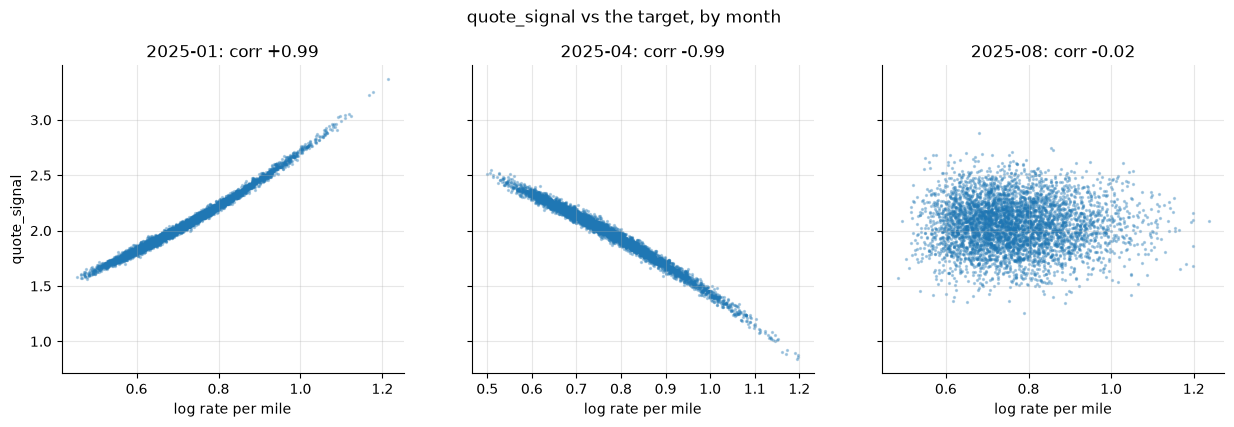

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, month in zip(ax, [1, 4, 8]):
    g = base[base.date.dt.month == month]
    x = np.log(g.posted_rate / g.distance)
    a.scatter(x, g.quote_signal, s=2, alpha=0.3)
    a.set_title(f"2025-{month:02d}: corr {np.corrcoef(g.quote_signal, x)[0, 1]:+.2f}")
    a.set_xlabel("log rate per mile")
ax[0].set_ylabel("quote_signal")
fig.suptitle("quote_signal vs the target, by month", y=1.02); plt.show()

In [31]:
# Can quote_signal be predicted from the load's features?  Within a normal training month: yes. August / validation: no.
qs_cols = ["log_distance", "equipment", "weight", "market_index", "day_of_week",
           "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]
def qs_r2(df):
    df = df.dropna(subset=["weight", "market_index"]).assign(weight=lambda d: d.weight.abs())
    return cross_val_score(HistGradientBoostingRegressor(max_iter=200, random_state=SEED), numeric_frame(df)[qs_cols],
                           df.quote_signal, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean()

for label, df in [("training, May", base[base.date.dt.month == 5]),
                  ("training, August", base[base.date.dt.month == 8]),
                  ("validation, November", raw_valid[raw_valid.date.dt.month == 11]),
                  ("validation, December", raw_valid[raw_valid.date.dt.month == 12])]:
    print(f"R² of quote_signal from load features, {label:<21} {qs_r2(df):6.3f}")

R² of quote_signal from load features, training, May          0.958


R² of quote_signal from load features, training, August      -0.134


R² of quote_signal from load features, validation, November  -0.100


R² of quote_signal from load features, validation, December  -0.127


- In 9 of 10 training months `quote_signal` correlates **±0.99** with log rate per mile: it is the target re-encoded,
  with the sign switching between months. Positive and negative months cancel out, which is why the overall
  correlation looked weak (≈ 0.1) in the EDA.
- In **August** and in **both validation months** it has no relationship with the load: its slope against distance is
  ~0 and load features cannot predict it (R² ≤ 0). August, the one month where we can check, shows it then carries no
  rate information either.
- A model trained with it would score superbly in random cross-validation and then fail on the real predictions.

**Decision: exclude `quote_signal` from every model.** It stays in the cleaned files for reference only.
This also explains 2.7: weight looked recoverable only because `quote_signal` encodes the rate, and the rate depends
on weight. The extreme `quote_signal` values need no treatment, since the column is not used.

## 2.9 `distance` and coordinates

In [32]:
lane = raw_train.groupby(["pickup", "delivery"]).distance
lane_dev = raw_train.distance / lane.transform("median") - 1
busy = lane.transform("size") >= 5
print("deviation from lane median distance (lanes with ≥5 loads), quantiles 0/0.1/1/50/99/99.9/100%:")
print(" ", lane_dev[busy].quantile([0, .001, .01, .5, .99, .999, 1]).round(3).tolist())
ok_rate = ~truth
rpm_ok = rpm[ok_rate]
print(f"loads at the 70-mile minimum: {(raw_train.distance == 70).sum()} | median rate/mile {rpm_ok[raw_train.distance[ok_rate] == 70].median():.2f}"
      f" vs 70–100 mi loads {rpm_ok[raw_train.distance[ok_rate].between(70.01, 100)].median():.2f}")

deviation from lane median distance (lanes with ≥5 loads), quantiles 0/0.1/1/50/99/99.9/100%:
  [-0.241, -0.113, -0.057, 0.0, 0.058, 0.133, 0.283]
loads at the 70-mile minimum: 48 | median rate/mile 3.05 vs 70–100 mi loads 2.89


Distances vary smoothly around each lane's typical value (different addresses within a city), with no outlying cluster.
Loads at the 70-mile minimum price like other short trips.
**Decision: keep distances; add a `distance_at_floor` flag.** Coordinates are consistent per city, so they are kept
as location features. The 8 cities that appear only in validation are handled in section 3.

## 2.10 Cleaning pipeline

Everything above combined. Learned on training data and applied unchanged to validation and December.

In [33]:
WEIGHT_CAP, WEIGHT_FLOOR, DISTANCE_FLOOR = 47_500, 5_000, 70.0

city_coords = (pd.concat([df[[side, f"{side}_lat", f"{side}_lon"]].set_axis(["city", "lat", "lon"], axis=1)
                          for df in (raw_train, raw_valid) for side in ("pickup", "delivery")])
               .drop_duplicates("city").set_index("city"))

def basic_fixes(df):
    out = df.copy()
    out["weight"] = out.weight.abs()                                        # 2.2 sign flips
    out["weight_at_cap"] = (out.weight == WEIGHT_CAP).astype(int)           # 2.3 capped values
    out["weight_at_floor"] = (out.weight == WEIGHT_FLOOR).astype(int)
    out["distance_at_floor"] = (out.distance == DISTANCE_FLOOR).astype(int) # 2.9
    return out

def fill_market_index(df, reference):
    """2.6: fill missing market_index with the same day's mean from `reference`."""
    out = df.copy()
    out["market_index_missing"] = out.market_index.isna().astype(int)
    out["market_index"] = out.market_index.fillna(out.date.map(reference.groupby("date").market_index.mean()))
    return out

def fill_weight(df):
    """2.7: fill missing weight with the training median."""
    out = df.copy()
    out["weight_missing"] = out.weight.isna().astype(int)
    out["weight"] = out.weight.fillna(WEIGHT_FILL)
    return out

# --- training data
train_clean = basic_fixes(raw_train[~IS_RATE_ERROR])                       # 2.4 drop wrong rates
train_clean = fill_market_index(train_clean, reference=train_clean)        # 2.6
WEIGHT_FILL = train_clean.weight.median()                                  # learned on training only
train_clean = fill_weight(train_clean)                                     # 2.7

# --- validation: same steps; market_index from validation's own same-day mean
valid_clean = fill_weight(fill_market_index(basic_fixes(raw_valid), reference=raw_valid))

# --- December chart inputs: add coordinates and market_index (quote_signal is not used by any model)
dec = raw_dec.drop(columns="predicted_rate").copy()
for side in ("pickup", "delivery"):
    dec[f"{side}_lat"] = dec[side].map(city_coords.lat)
    dec[f"{side}_lon"] = dec[side].map(city_coords.lon)
dec["market_index"] = dec.date.map(raw_valid.groupby("date").market_index.mean())   # same-day mean from validation
december_clean = fill_weight(basic_fixes(dec)).assign(market_index_missing=0)

print("train:", train_clean.shape, "| validation:", valid_clean.shape, "| december:", december_clean.shape)
print(f"weight fill value: {WEIGHT_FILL:,.0f} lb")
december_clean[["date", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "market_index"]].head()

train: (47323, 19) | validation: (12000, 18) | december: (31, 16)
weight fill value: 31,508 lb


,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index
0,2025-12-01,36.99152,-84.99876,41.31561,-85.36206,0.834919
1,2025-12-02,36.99152,-84.99876,41.31561,-85.36206,0.914680
2,2025-12-03,36.99152,-84.99876,41.31561,-85.36206,0.994063
3,2025-12-04,36.99152,-84.99876,41.31561,-85.36206,1.024021
4,2025-12-05,36.99152,-84.99876,41.31561,-85.36206,0.975120


## 2.11 Final checks and saved files

                     rows  missing weight  missing market_index  negative weight wrong rates
train (raw)         48000             300                   374              292         677
train (clean)       47323               0                     0                0           0
validation (raw)    12000             165                   249              145         n/a
validation (clean)  12000               0                     0                0         n/a 



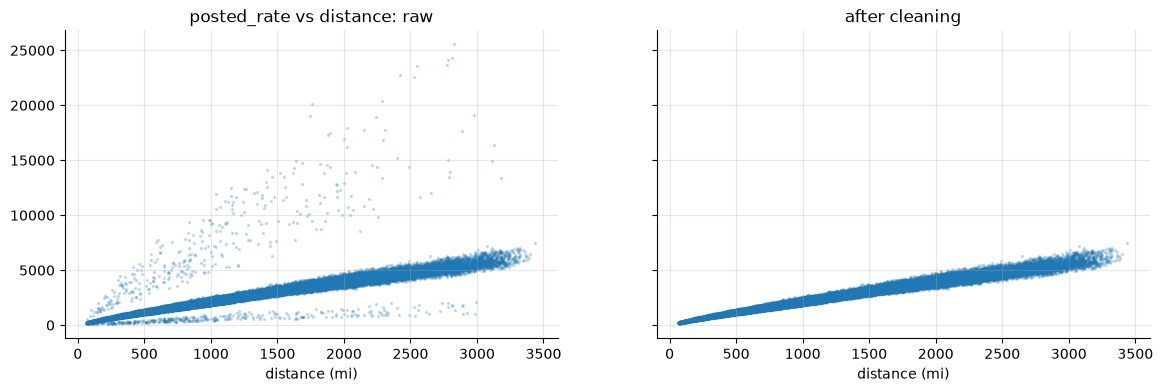

saved: ['december_clean.csv', 'train_clean.csv', 'validation_clean.csv']


In [34]:
# Columns available to models. quote_signal is deliberately excluded (2.8).
MODEL_INPUT_COLS = ["pickup", "delivery", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "distance",
                    "equipment", "weight", "date", "market_index",
                    "weight_at_cap", "weight_at_floor", "distance_at_floor", "market_index_missing", "weight_missing"]

for name, df in [("train", train_clean), ("validation", valid_clean), ("december", december_clean)]:
    assert df[MODEL_INPUT_COLS].notna().all().all(), f"{name} still has missing values"
    assert (df.weight > 0).all() and df.weight.between(WEIGHT_FLOOR, WEIGHT_CAP).all(), f"{name} weight out of range"
assert len(valid_clean) == 12_000 and set(valid_clean.load_id) == set(raw_valid.load_id)
assert len(december_clean) == 31

summary = pd.DataFrame({
    "rows": [len(raw_train), len(train_clean), len(raw_valid), len(valid_clean)],
    "missing weight": [raw_train.weight.isna().sum(), train_clean.weight.isna().sum(), raw_valid.weight.isna().sum(), valid_clean.weight.isna().sum()],
    "missing market_index": [raw_train.market_index.isna().sum(), train_clean.market_index.isna().sum(),
                             raw_valid.market_index.isna().sum(), valid_clean.market_index.isna().sum()],
    "negative weight": [(raw_train.weight < 0).sum(), (train_clean.weight < 0).sum(), (raw_valid.weight < 0).sum(), (valid_clean.weight < 0).sum()],
    "wrong rates": [int(IS_RATE_ERROR.sum()), 0, "n/a", "n/a"],
}, index=["train (raw)", "train (clean)", "validation (raw)", "validation (clean)"])
print(summary.to_string(), "\n")

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax[0].scatter(raw_train.distance, raw_train.posted_rate, s=2, alpha=0.2); ax[0].set_title("posted_rate vs distance: raw")
ax[1].scatter(train_clean.distance, train_clean.posted_rate, s=2, alpha=0.2); ax[1].set_title("after cleaning")
for a in ax: a.set_xlabel("distance (mi)")
plt.show()

CLEAN_DIR = Path("data_clean"); CLEAN_DIR.mkdir(exist_ok=True)
train_clean.to_csv(CLEAN_DIR / "train_clean.csv", index=False)
valid_clean.to_csv(CLEAN_DIR / "validation_clean.csv", index=False)
december_clean.to_csv(CLEAN_DIR / "december_clean.csv", index=False)
print("saved:", sorted(p.name for p in CLEAN_DIR.iterdir()))

## 2.12 Cleaning summary

| Issue | Evidence | Methods compared | Decision |
|---|---|---|---|
| Wrong `posted_rate` | Model residuals form 3 groups with empty gaps | IQR, z-score, IQR on rate/mile, Isolation Forest, group-median ratio, model residual | **Drop** rows beyond the gap (model residual, out-of-fold) |
| Negative `weight` | Absolute values match the positive distribution (KS), normal rates | drop, fill in, absolute value | **Absolute value** |
| `weight` at 47,500 cap / 5,000 floor | Spike at cap; prices like heavy loads | drop, fill in, keep | **Keep + flag** |
| Missing `market_index` | Random; a daily value + small noise | 7 methods (masking test), re-checked on validation | **Same-day mean + flag** |
| Missing `weight` | Random; no feature predicts it out of time | 6 methods in-month + 4 out of time on validation | **Training median + flag** |
| `quote_signal` | ±0.99 correlation with the rate in 9/10 training months; noise in August and validation | — | **Exclude from all models** (target leakage) |
| Distance variation / 70-mile minimum | Smooth around lane typical value; prices like short trips | — | **Keep + flag floor** |
| December file lacks coordinates, `market_index`, `quote_signal` | — | — | City lookup · validation same-day mean · `quote_signal` not needed |

**Lesson carried into modelling:** two features (`market_index`'s link to rates, and `quote_signal`) behave differently
in later months than in earlier ones. Random-split tests hid both problems; out-of-time tests exposed them.
Section 4 therefore validates on later months only.

---
# 3. Feature engineering

**Approach**
1. Build candidate features from how freight is priced: distance shape, location, calendar, market.
2. Score every idea on **time-based holdouts**: train on earlier months, test on the next two, which mimics the real
   task (Jan–Oct → Nov–Dec). Three windows: **Jan–Apr → May–Jun**, **Jan–Jun → Jul–Aug**, **Jan–Aug → Sep–Oct**.
3. Use two reference models, because what helps one can be useless to the other: **gradient boosting** (trees) and
   **Ridge** (linear).
4. Keep a feature only if it lowers the error across the windows. Compare that selection with **PCA**.

Metric: mean absolute error in dollars (MAE). `quote_signal` is excluded throughout (section 2.8).

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

ALL_ROWS = pd.concat([train_clean, valid_clean])
CITY_XY = city_coords                                         # from 2.10
DAILY_MI = ALL_ROWS.groupby("date").market_index.mean().sort_index()   # an input, available for every date
VOLUME = (ALL_ROWS.pickup.value_counts(), ALL_ROWS.delivery.value_counts())


def city_levels(fit, k=5, prior=50):
    """Price level of each city (shared by pickup and delivery), from `fit` rows, after removing distance and
    equipment effects. Small cities are shrunk toward 0. Cities absent from `fit` get the mean of their k nearest
    known cities by coordinates."""
    f = fit.assign(lrpm=np.log(fit.posted_rate / fit.distance), dband=pd.qcut(fit.distance, 20, duplicates="drop"))
    f["adj"] = f.lrpm - f.groupby(["equipment", "dband"], observed=True).lrpm.transform("mean")
    both = pd.concat([f[["pickup", "adj"]].set_axis(["city", "adj"], axis=1),
                      f[["delivery", "adj"]].set_axis(["city", "adj"], axis=1)])
    g = both.groupby("city").adj.agg(["sum", "count"])
    level = g["sum"] / (g["count"] + prior)
    known_xy = CITY_XY.loc[level.index, ["lat", "lon"]].to_numpy()
    out = {}
    for city in CITY_XY.index:
        if city in level.index:
            out[city] = level[city]
        else:
            dist = np.hypot(*(known_xy - CITY_XY.loc[city, ["lat", "lon"]].to_numpy()).T)
            out[city] = level.iloc[np.argsort(dist)[:k]].mean()
    return pd.Series(out)


def oof_city_levels(fit, n_folds=5):
    """Out-of-fold city levels for training rows, so no row helps encode its own target."""
    fold = np.random.default_rng(SEED).integers(0, n_folds, len(fit))
    p, d = np.empty(len(fit)), np.empty(len(fit))
    for k in range(n_folds):
        lv = city_levels(fit[fold != k])
        p[fold == k] = fit.pickup[fold == k].map(lv).to_numpy()
        d[fold == k] = fit.delivery[fold == k].map(lv).to_numpy()
    return p, d


def bearing(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    return np.degrees(np.arctan2(np.sin(lon2 - lon1) * np.cos(lat2),
                                 np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)))


def build_features(df, pickup_level, delivery_level):
    """Every candidate feature."""
    X = pd.DataFrame(index=df.index)
    # base inputs
    for c in ["distance", "weight", "market_index", "equipment", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]:
        X[c] = df[c]
    # distance shape: fixed costs are spread over fewer miles on short trips
    X["log_distance"] = np.log(df.distance)
    X["inv_distance"] = 1 / df.distance
    # data-quality flags from section 2
    for c in ["weight_at_cap", "weight_at_floor", "distance_at_floor", "weight_missing", "market_index_missing"]:
        X[c] = df[c]
    # calendar
    X["day_of_week"] = df.date.dt.dayofweek
    X["day_of_month"] = df.date.dt.day
    X["days_to_month_end"] = df.date.dt.days_in_month - df.date.dt.day
    X["day_of_year"] = df.date.dt.dayofyear
    # market_index variants
    slow = DAILY_MI.rolling(7, center=True, min_periods=4).mean()
    X["mi_day_mean"] = df.date.map(DAILY_MI)
    X["mi_7d_mean"] = df.date.map(slow)
    X["mi_dev_from_day"] = df.market_index - X.mi_day_mean
    X["mi_week"] = df.date.map(DAILY_MI - slow)          # weekly cycle part
    X["mi_slow"] = X["mi_7d_mean"]                       # slow trend part
    # location
    X["pickup_level"] = pickup_level
    X["delivery_level"] = delivery_level
    X["lane_level"] = np.asarray(pickup_level) + np.asarray(delivery_level)
    X["d_lat"] = df.delivery_lat - df.pickup_lat
    X["d_lon"] = df.delivery_lon - df.pickup_lon
    X["bearing"] = bearing(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
    X["circuity"] = df.distance / np.maximum(haversine_miles(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon), 1)
    out_ct, in_ct = VOLUME
    for side in ("pickup", "delivery"):
        o, i = df[side].map(out_ct), df[side].map(in_ct)
        X[f"{side}_imbalance"] = ((o - i) / (o + i)).fillna(0)
    return X


GROUPS = {
    "base": ["distance", "weight", "market_index", "equipment", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"],
    "distance_shape": ["log_distance", "inv_distance"],
    "flags": ["weight_at_cap", "weight_at_floor", "distance_at_floor", "weight_missing", "market_index_missing"],
    "day_of_week": ["day_of_week"],
    "day_of_month": ["day_of_month", "days_to_month_end"],
    "day_of_year": ["day_of_year"],
    "market_smoothing": ["mi_day_mean", "mi_7d_mean", "mi_dev_from_day"],
    "city_levels": ["pickup_level", "delivery_level", "lane_level"],
    "geometry": ["d_lat", "d_lon", "bearing", "circuity"],
    "imbalance": ["pickup_imbalance", "delivery_imbalance"],
}
cols_of = lambda groups: [c for g in groups for c in GROUPS[g]]
ALL_CANDIDATES = cols_of(GROUPS) + ["mi_week", "mi_slow"]
print(f"{len(ALL_CANDIDATES)} candidate features in {len(GROUPS)} groups")

33 candidate features in 10 groups


In [36]:
WINDOWS = {"May–Jun": (range(1, 5), (5, 6)), "Jul–Aug": (range(1, 7), (7, 8)), "Sep–Oct": (range(1, 9), (9, 10))}

def make_window(train_months, test_months):
    tr = train_clean[train_clean.date.dt.month.isin(train_months)].reset_index(drop=True)
    te = train_clean[train_clean.date.dt.month.isin(test_months)].reset_index(drop=True)
    p_tr, d_tr = oof_city_levels(tr)          # city levels learned only from the training part
    lv = city_levels(tr)
    return tr, te, build_features(tr, p_tr, d_tr), build_features(te, te.pickup.map(lv).to_numpy(), te.delivery.map(lv).to_numpy())

windows = {name: make_window(*w) for name, w in WINDOWS.items()}

TARGETS = {   # (transform, inverse)
    "rate": (lambda d: d.posted_rate, lambda p, d: p),
    "log_rate": (lambda d: np.log(d.posted_rate), lambda p, d: np.exp(p)),
    "rate_per_mile": (lambda d: d.posted_rate / d.distance, lambda p, d: p * d.distance),
    "log_rate_per_mile": (lambda d: np.log(d.posted_rate / d.distance), lambda p, d: np.exp(p) * d.distance),
}

def gbm_model(**kw):
    return HistGradientBoostingRegressor(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, random_state=SEED, **kw)

def fit_predict(model, cols, tr, te, Xtr, Xte, target="log_rate", pca=None):
    fwd, inv = TARGETS[target]
    cat = "equipment" in cols
    if model == "gbm":
        A, B = Xtr[cols].copy(), Xte[cols].copy()
        if cat:
            A["equipment"] = pd.Categorical(A.equipment, categories=EQUIPMENT).codes
            B["equipment"] = pd.Categorical(B.equipment, categories=EQUIPMENT).codes
        if pca:
            prep = make_pipeline(StandardScaler(), PCA(n_components=pca, random_state=SEED))
            A, B = prep.fit_transform(A), prep.transform(B)
            m = gbm_model()
        else:
            m = gbm_model(categorical_features=[cols.index("equipment")] if cat else None)
        m.fit(A, fwd(tr)); p = m.predict(B)
    else:
        num = [c for c in cols if c != "equipment"]
        ct = ColumnTransformer([("num", StandardScaler(), num)] + ([("cat", OneHotEncoder(), ["equipment"])] if cat else []))
        steps = [ct] + ([PCA(n_components=pca, random_state=SEED)] if pca else []) + [Ridge(alpha=1.0)]
        m = make_pipeline(*steps).fit(Xtr[cols], fwd(tr)); p = m.predict(Xte[cols])
    return np.asarray(inv(p, te))

def window_mae(model, cols, pca=None, target="log_rate"):
    """MAE ($) in each time window."""
    return pd.Series({name: mean_absolute_error(te.posted_rate, fit_predict(model, cols, tr, te, Xtr, Xte, target, pca))
                      for name, (tr, te, Xtr, Xte) in windows.items()})
print({k: (len(v[0]), len(v[1])) for k, v in windows.items()}, "(train rows, test rows)")

{'May–Jun': (18835, 9571), 'Jul–Aug': (28406, 9538), 'Sep–Oct': (37944, 9379)} (train rows, test rows)


## 3.1 Baseline and target

A naive baseline: each equipment type's median rate per mile × distance. Then gradient boosting on the base inputs
with four ways of expressing the target.

In [37]:
def naive(tr, te):
    rpm = (tr.posted_rate / tr.distance).groupby(tr.equipment).median()
    return te.equipment.map(rpm) * te.distance
naive_mae = pd.Series({n: mean_absolute_error(te.posted_rate, naive(tr, te)) for n, (tr, te, _, _) in windows.items()})
rows = {"naive: median rate/mile × distance": naive_mae}
base_cols = cols_of(["base", "distance_shape"])
for target in TARGETS:
    rows[f"gradient boosting, target = {target}"] = window_mae("gbm", base_cols, target=target)
res = pd.DataFrame(rows).T
res["mean"] = res.mean(axis=1)
res.round(1)

,May–Jun,Jul–Aug,Sep–Oct,mean
naive: median rate/mile × distance,153.7,172.4,175.1,167.1
"gradient boosting, target = rate",63.2,52.3,105.1,73.5
"gradient boosting, target = log_rate",63.2,51.9,106.4,73.8
"gradient boosting, target = rate_per_mile",60.2,51.0,105.7,72.3
"gradient boosting, target = log_rate_per_mile",60.5,51.5,106.3,72.8


All four target forms are within about $1 of each other. **Decision: predict log(rate)** and convert back. It
treats effects as percentages (natural for prices) and can never produce a negative rate, which the scorer rejects.

## 3.2 Signals behind the location and market features

corr(city level, mean of its 1 nearest cities): 0.943
corr(city level, mean of its 3 nearest cities): 0.944
corr(city level, mean of its 5 nearest cities): 0.954
corr(city level, latitude): -0.857
stability: corr(levels from Jan–May, levels from Jun–Oct) = 0.983


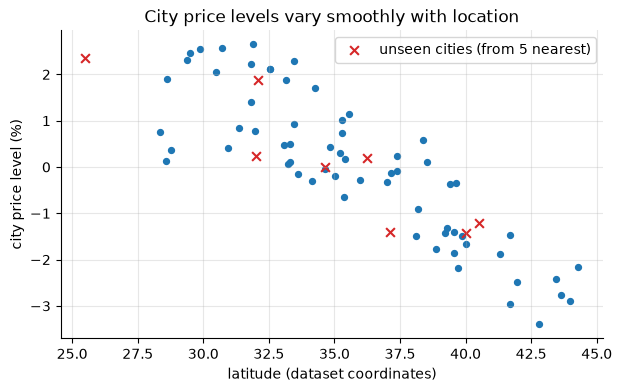

In [38]:
# City price levels: is a city's level similar to its neighbours'? (decides how to handle the 8 unseen cities)
lv_all = city_levels(train_clean)
known = [c for c in lv_all.index if c in set(train_clean.pickup) | set(train_clean.delivery)]
xy = CITY_XY.loc[known, ["lat", "lon"]].to_numpy()
for k in (1, 3, 5):
    nn_mean = [lv_all[known].iloc[np.argsort(np.hypot(*(xy - xy[i]).T))[1:k + 1]].mean() for i in range(len(known))]
    print(f"corr(city level, mean of its {k} nearest cities): {np.corrcoef(lv_all[known], nn_mean)[0, 1]:.3f}")
print(f"corr(city level, latitude): {np.corrcoef(lv_all[known], xy[:, 0])[0, 1]:.3f}")
half = lambda months: city_levels(train_clean[train_clean.date.dt.month.isin(months)])
print(f"stability: corr(levels from Jan–May, levels from Jun–Oct) = {half(range(1, 6))[known].corr(half(range(6, 11))[known]):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xy[:, 0], lv_all[known] * 100, s=18)
unseen_c = [c for c in lv_all.index if c not in known]
ax.scatter(CITY_XY.loc[unseen_c, "lat"], lv_all[unseen_c] * 100, s=40, marker="x", color="C3", label="unseen cities (from 5 nearest)")
ax.set_xlabel("latitude (dataset coordinates)"); ax.set_ylabel("city price level (%)"); ax.legend()
ax.set_title("City price levels vary smoothly with location"); plt.show()

In [39]:
# market_index = slow trend + weekly cycle. Which part still tracks rates?
lrpm = np.log(train_clean.posted_rate / train_clean.distance)
dband = pd.qcut(train_clean.distance, 20)
adj = lrpm - lrpm.groupby([train_clean.equipment, dband], observed=True).transform("mean")
level = adj.groupby(train_clean.date).mean()
slow_mi = DAILY_MI.rolling(7, center=True, min_periods=4).mean()
week_mi = DAILY_MI - slow_mi
level_slow = level.rolling(7, center=True, min_periods=4).mean()
level_week = level - level_slow
rows = {}
for name, mask in [("Jan–Jul", level.index.month <= 7), ("Aug–Oct", level.index.month >= 8), ("Sep–Oct", level.index.month >= 9)]:
    rows[name] = {"weekly part: corr with rate level": np.corrcoef(level_week[mask], week_mi.reindex(level.index)[mask])[0, 1],
                  "slow part: corr with rate level": np.corrcoef(level_slow[mask], slow_mi.reindex(level.index)[mask])[0, 1]}
pd.DataFrame(rows).round(3)

,Jan–Jul,Aug–Oct,Sep–Oct
weekly part: corr with rate level,0.894,0.832,0.771
slow part: corr with rate level,0.937,-0.618,-0.205


- **City levels** are smooth over the map (a city's level ≈ its neighbours') and stable over time. So unseen cities
  get the mean level of their 5 nearest known cities, and raw coordinates also carry location.
- **`market_index` is two signals.** Its weekly cycle tracks rates all year. Its slow trend tracked rates until July and
  then broke. That is the main reason time features and market features compete below.

## 3.3 Which feature groups help? (drop one group at a time)

Starting from all candidates, remove one group and measure the change in MAE in each window.
**Positive = the group helps** (removing it makes the error worse).

In [40]:
ablation = {}
for model in ("gbm", "ridge"):
    full = window_mae(model, ALL_CANDIDATES)
    rows = {"(all candidates) MAE": full}
    for g in [g for g in GROUPS if g != "base"]:
        rows[f"drop {g}"] = window_mae(model, [c for c in ALL_CANDIDATES if c not in GROUPS[g]]) - full
    mi_all = ["market_index", "mi_day_mean", "mi_7d_mean", "mi_dev_from_day", "mi_week", "mi_slow"]
    rows["drop every market_index feature"] = window_mae(model, [c for c in ALL_CANDIDATES if c not in mi_all]) - full
    t = pd.DataFrame(rows).T
    t["mean"] = t.mean(axis=1)
    ablation[model] = t
pd.concat(ablation, axis=1).round(1)

gbm                         ridge                       
                                May–Jun Jul–Aug Sep–Oct  mean May–Jun Jul–Aug Sep–Oct   mean
(all candidates) MAE               73.3    96.9    57.8  76.0    41.4   212.4    55.2  103.0
drop distance_shape                 0.7    -2.8     0.1  -0.7   330.6   154.3   329.1  271.3
drop flags                         -0.1    -1.3    -0.3  -0.6     0.2    -0.1     0.2    0.1
drop day_of_week                    0.1    -0.3    -0.3  -0.2    -0.0     0.0    -0.0    0.0
drop day_of_month                 -11.2    10.4    -1.3  -0.7    -0.7    -9.4    -2.2   -4.1
drop day_of_year                   -0.0   -37.0    60.6   7.9    11.8  -162.6    54.1  -32.2
drop market_smoothing               1.7    -1.1     0.7   0.4    -0.0    -0.1    -0.0   -0.0
drop city_levels                    1.1    -3.9    -0.1  -1.0     5.9    -2.9     4.7    2.5
drop geometry                       0.9    -0.8     0.3   0.1    -0.0     0.1    -0.0    0.0
drop imbalance                      0.7    -0.6     0.6   0.2    -0.0     0.1     0.0    0.0
drop every market_index feature     5.9    38.7    -5.9  12.9     3.1   -33.6    38.6    2.7

- Most groups change the error by only a dollar or two, which is noise. **Flags, imbalance and day-of-month** never
  help consistently (day-of-month swings between −$11 and +$10), so they are dropped.
- The **distance shape** and **city levels** are essential for the linear model; trees work them out on their own.
- **Day of year and the market features dominate, and they trade off by window.** Trees treat future dates like the
  last training date, so day of year means "prices stay at the latest level". That wins in Sep–Oct and fails in
  Jul–Aug, when the market turned and `market_index` saw it.

## 3.4 How to use `market_index`

In [41]:
core = ["distance", "log_distance", "inv_distance", "weight", "equipment", "pickup_lat", "pickup_lon", "delivery_lat",
        "delivery_lon", "pickup_level", "delivery_level", "lane_level", "d_lat", "d_lon", "bearing", "circuity",
        "day_of_week", "day_of_year"]
variants = {"no market features": [], "raw market_index": ["market_index"],
            "smoothed set (day mean, 7-day mean, deviation)": ["mi_day_mean", "mi_7d_mean", "mi_dev_from_day"],
            "weekly part + slow part": ["mi_week", "mi_slow"], "weekly part only": ["mi_week"]}
mi_table = {}
for model in ("gbm", "ridge"):
    for name, extra in variants.items():
        mi_table[(model, name)] = window_mae(model, core + extra)
mi_table = pd.DataFrame(mi_table).T
mi_table["mean"] = mi_table.mean(axis=1)
mi_table.round(1)

May–Jun  Jul–Aug  Sep–Oct   mean
gbm   no market features                                 62.3    151.3     52.7   88.8
      raw market_index                                   60.5    107.8     56.6   74.9
      smoothed set (day mean, 7-day mean, deviation)     61.5    103.9     57.2   74.2
      weekly part + slow part                            64.7    148.9     53.4   89.0
      weekly part only                                   63.8    148.8     51.2   87.9
ridge no market features                                 43.9    178.1     95.8  105.9
      raw market_index                                   43.5    102.1     48.0   64.6
      smoothed set (day mean, 7-day mean, deviation)     40.9    203.0     53.2   99.0
      weekly part + slow part                            41.3    203.0     53.6   99.3
      weekly part only                                   41.2    179.6     95.8  105.5

**Decision: raw `market_index`.** It is clearly best for the linear model and within $1 of the best for trees.
"Weekly part only" wins in Sep–Oct (−$5) but loses $41 in Jul–Aug, the window where the market turned. Raw `market_index` is the better protection if
the market turns again. It also makes little difference for the real forecast: Nov–Dec index values look like
Sep–Oct's, and both versions predict Nov–Dec rates within about 0.5% of each other.

## 3.5 Feature selection: chosen features vs all candidates vs PCA

In [42]:
SELECTED = core + ["market_index"]                       # 19 features
COMPACT = ["distance", "weight", "equipment", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
           "day_of_week", "day_of_year", "market_index"]  # 10 features
selection = {}
for model in ("gbm", "ridge"):
    for name, cols, pca in [("all candidates", ALL_CANDIDATES, None), ("selected (19)", SELECTED, None),
                            ("compact (10)", COMPACT, None), ("PCA 95% variance on selected", SELECTED, 0.95),
                            ("PCA 99% variance on selected", SELECTED, 0.99), ("PCA 95% variance on all", ALL_CANDIDATES, 0.95)]:
        selection[(model, name)] = window_mae(model, cols, pca=pca)
selection = pd.DataFrame(selection).T
selection["mean"] = selection.mean(axis=1)
n_comp = make_pipeline(StandardScaler(), PCA(0.95)).fit(windows["Sep–Oct"][2][[c for c in SELECTED if c != "equipment"]])[-1].n_components_
print(f"PCA at 95% variance keeps {n_comp} components from {len(SELECTED) - 1} numeric features\n")
selection.round(1)

PCA at 95% variance keeps 11 components from 18 numeric features



May–Jun  Jul–Aug  Sep–Oct   mean
gbm   all candidates                   73.3     96.9     57.8   76.0
      selected (19)                    60.5    107.8     56.6   74.9
      compact (10)                     61.0    107.6     56.9   75.2
      PCA 95% variance on selected     65.7     78.7     56.8   67.1
      PCA 99% variance on selected     77.4     97.8     56.7   77.3
      PCA 95% variance on all         103.0     62.5     75.9   80.5
ridge all candidates                   41.4    212.4     55.2  103.0
      selected (19)                    43.5    102.1     48.0   64.6
      compact (10)                    421.7    399.4    427.3  416.1
      PCA 95% variance on selected    111.6    115.0     99.0  108.5
      PCA 99% variance on selected    112.0    125.8    115.0  117.6
      PCA 95% variance on all         140.7    136.6    143.2  140.1

PCA hurts the linear model badly. For trees, "PCA 95%" has a lower mean, but only because of Jul–Aug, and the 99%
version shows nothing similar. The next cell checks where that gain comes from.

In [43]:
no_doy = [c for c in SELECTED if c != "day_of_year"]
diag = {"selected": window_mae("gbm", SELECTED), "selected without day_of_year": window_mae("gbm", no_doy),
        "PCA 95% on selected": window_mae("gbm", SELECTED, pca=0.95),
        "PCA 95% on selected without day_of_year": window_mae("gbm", no_doy, pca=0.95)}
diag = pd.DataFrame(diag).T
diag["mean"] = diag.mean(axis=1)
print(diag.round(1), "\n")

tr, te, Xtr, Xte = windows["Jul–Aug"]
frozen = Xte.assign(day_of_year=Xtr.day_of_year.max())     # every test day presented as the last training day
for name, pca in [("plain trees", None), ("PCA 95% trees", 0.95)]:
    a = mean_absolute_error(te.posted_rate, fit_predict("gbm", SELECTED, tr, te, Xtr, Xte, pca=pca))
    b = mean_absolute_error(te.posted_rate, fit_predict("gbm", SELECTED, tr, te, Xtr, frozen, pca=pca))
    print(f"Jul–Aug, {name:<14}: MAE {a:6.1f}  →  {b:6.1f} when every test date is set to the last training date")

                                         May–Jun  Jul–Aug  Sep–Oct  mean
selected                                    60.5    107.8     56.6  74.9
selected without day_of_year                63.1     54.9    116.1  78.0
PCA 95% on selected                         65.7     78.7     56.8  67.1
PCA 95% on selected without day_of_year     74.0     63.5    117.1  84.9 



Jul–Aug, plain trees   : MAE  107.8  →   107.8 when every test date is set to the last training date


Jul–Aug, PCA 95% trees : MAE   78.7  →    57.7 when every test date is set to the last training date


- Without `day_of_year`, PCA is **worse than plain features in every window**. It does not find better features.
- Plain trees give the same answer whether future dates are shown as-is or as the last training date, so they are
  predictable. The PCA model's Jul–Aug error changes by about $21 from that change alone: its "gain" comes from mixing the
  date into rotated components, which changes how strongly it trusts the latest price level. That is accidental
  and fragile.

**Decision: no PCA.** The real open question it exposed, how much to trust the latest price level versus
`market_index`, is a modelling choice and is handled in section 5 (e.g. combining models with and without
`day_of_year`).

## 3.6 Final features

In [44]:
TREE_FEATURES = COMPACT        # trees: 10 features match the 19-feature set
LINEAR_FEATURES = SELECTED     # linear / neural models need the engineered distance, city-level and geometry features

# Final matrices: city levels learned on all training rows (out-of-fold for the training rows themselves)
p_tr, d_tr = oof_city_levels(train_clean)
levels_final = city_levels(train_clean)
X_train = build_features(train_clean, p_tr, d_tr)
X_valid = build_features(valid_clean, valid_clean.pickup.map(levels_final).to_numpy(), valid_clean.delivery.map(levels_final).to_numpy())
X_dec = build_features(december_clean, december_clean.pickup.map(levels_final).to_numpy(), december_clean.delivery.map(levels_final).to_numpy())
y_train = np.log(train_clean.posted_rate)

for name, X in [("train", X_train), ("validation", X_valid), ("december", X_dec)]:
    assert X[LINEAR_FEATURES].notna().all().all(), name
print("train", X_train[LINEAR_FEATURES].shape, "| validation", X_valid[LINEAR_FEATURES].shape, "| december", X_dec[LINEAR_FEATURES].shape)
print("\ntree features:  ", TREE_FEATURES)
print("linear features:", LINEAR_FEATURES)
print("\nunseen-city levels (from nearest neighbours):", levels_final[unseen_c].mul(100).round(2).to_dict())

train (47323, 19) | validation (12000, 19) | december (31, 19)

tree features:   ['distance', 'weight', 'equipment', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'day_of_week', 'day_of_year', 'market_index']
linear features: ['distance', 'log_distance', 'inv_distance', 'weight', 'equipment', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'pickup_level', 'delivery_level', 'lane_level', 'd_lat', 'd_lon', 'bearing', 'circuity', 'day_of_week', 'day_of_year', 'market_index']

unseen-city levels (from nearest neighbours): {'Norfolk': -1.4, 'Allentown': -1.43, 'Knoxville': 0.19, 'Laredo': 2.36, 'Jackson': 1.88, 'Charlotte': -0.0, 'Chicago': -1.22, 'San Diego': 0.23}


## 3.7 Feature-engineering summary

| Feature / idea | Result | Decision |
|---|---|---|
| Target as log(rate) | Ties with other target forms; always positive | **Use** |
| `distance`, `log_distance`, `1/distance` | Essential for the linear model (saves ~$270) | **Use** (linear); trees need only `distance` |
| `equipment`, `weight` | Largest drop-one losses for trees | **Use** |
| Coordinates | Carry location; cover unseen cities | **Use** |
| City price levels (out-of-fold, neighbour fallback for unseen cities) | Help the linear model; trees learn it from coordinates | **Use** (linear) |
| Geometry (Δlat, Δlon, bearing, circuity) | Small help | **Use** (linear) |
| `day_of_week` | Small, consistent | **Use** |
| `day_of_year` | Large, but window-dependent ("latest price level") | **Use**; trade-off handled in section 5 |
| Raw `market_index` | Best market design on average | **Use** |
| Smoothed / decomposed `market_index` | No better than raw on average | Drop |
| Day of month | Unstable (−$11 to +$10 between windows) | Drop |
| Data-quality flags, city imbalance | No consistent help | Drop |
| `quote_signal` | Target leakage (2.8) | Excluded |
| PCA | Hurts linear; tree "gain" is an artefact of date handling | **Not used** |

---
# 4. Validation strategy & train/test split

**The task is a forecast**: train on Jan–Oct, predict Nov–Dec. A useful test has to have the same shape, so
the validation always **trains on the past and tests on the following two months**:

- **Expanding windows**: Jan–Apr → May–Jun, Jan–Jun → Jul–Aug, Jan–Aug → Sep–Oct (the windows used since section 3).
- **Selection rule**: lowest **mean MAE across the three windows**; the worst window is reported too, as a measure of risk.
- **No leakage inside a window**: city price levels are learned only from that window's training months
  (out-of-fold for the training rows); settings are compared on the same windows; nothing from a test period is used to fit.
- **Final model**: retrained on all of Jan–Oct with the chosen settings, then applied to `validation.csv`.
- `validation.csv` has no labels, so the windows are the only honest accuracy estimate before Spotter scores it.

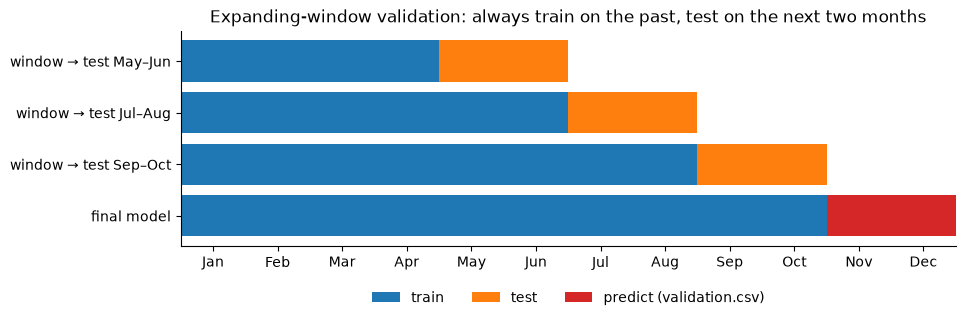

In [45]:
fig, ax = plt.subplots(figsize=(10, 2.8))
plan = [(f"window → test {n}", tr_m, te_m) for n, (tr_m, te_m) in WINDOWS.items()] + [("final model", range(1, 11), (11, 12))]
for i, (label, tr_m, te_m) in enumerate(plan):
    ax.barh(i, len(tr_m), left=0.5, color="C0", label="train" if i == 0 else None)
    final = i == len(plan) - 1
    ax.barh(i, len(te_m), left=min(te_m) - 0.5, color="C3" if final else "C1",
            label="predict (validation.csv)" if final else ("test" if i == 0 else None))
ax.set_yticks(range(len(plan)), [p[0] for p in plan]); ax.invert_yaxis()
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.5, 12.5); ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.set_title("Expanding-window validation: always train on the past, test on the next two months")
plt.show()

## 4.1 Why not a random split?

Same model, same features, two ways of testing it. A random split lets the model train on days from the same weeks
it is tested on, so it never has to forecast. The second comparison adds the leaked `quote_signal` (section 2.8)
to show which test would have caught it.

In [46]:
def random_split_mae(cols, extra=None):
    X = X_train[cols].assign(equipment=pd.Categorical(X_train.equipment, categories=EQUIPMENT).codes)
    if extra is not None:
        X = X.assign(**extra)
    model = gbm_model(categorical_features=[cols.index("equipment")])
    pred = np.exp(cross_val_predict(model, X, y_train, cv=KFold(5, shuffle=True, random_state=SEED)))
    return mean_absolute_error(train_clean.posted_rate, pred)

def time_window_mae_with_qs(cols):
    out = {}
    for name, (tr, te, Xtr, Xte) in windows.items():
        A = Xtr[cols].assign(quote_signal=tr.quote_signal.to_numpy())
        B = Xte[cols].assign(quote_signal=te.quote_signal.to_numpy())
        for M in (A, B):
            M["equipment"] = pd.Categorical(M.equipment, categories=EQUIPMENT).codes
        m = gbm_model(categorical_features=[cols.index("equipment")]).fit(A, np.log(tr.posted_rate))
        out[name] = mean_absolute_error(te.posted_rate, np.exp(m.predict(B)))
    return pd.Series(out)

split_check = pd.DataFrame({
    "random 5-fold split": [random_split_mae(TREE_FEATURES),
                            random_split_mae(TREE_FEATURES, {"quote_signal": train_clean.quote_signal.to_numpy()})],
    "time windows (mean)": [window_mae("gbm", TREE_FEATURES).mean(), time_window_mae_with_qs(TREE_FEATURES).mean()],
}, index=["tree model, chosen features", "tree model + quote_signal (leak)"])
split_check.round(1)

,random 5-fold split,time windows (mean)
"tree model, chosen features",34.2,75.2
tree model + quote_signal (leak),28.8,73.5


- A random split reports roughly **half** the error that forecasting actually produces. It would make every model look
  better than it is, and it would rank models by how well they fill gaps in the past rather than predict the future.
- Adding the leaked `quote_signal`: the random split rewards it strongly (about −16%), so it would have recommended
  the leak. The time windows give it only a small gain (about −2%), and only because most test months are themselves
  leaky months. In Nov–Dec it carries no information at all (section 2.8), so the random split badly overstates its value.

**Decision: expanding time windows** for all model selection, as above.

---
# 5. Models

Candidates, all scored on the three windows with log(rate) as the target:
- **Ridge** (linear, 19 features), **gradient boosting** in two implementations (**LightGBM** and scikit-learn's
  `HistGradientBoostingRegressor`; 10 features) and a **neural network** (`MLPRegressor`, 19 features)
- variants: tuned settings, absolute-error loss, recency weighting (recent days count more), without `day_of_year`
- combinations: averages, and a **hybrid** where Ridge sets the overall level and gradient boosting corrects what
  Ridge misses

On macOS, LightGBM needs the OpenMP library: `brew install libomp`.

In [47]:
import lightgbm as lgb
from sklearn.neural_network import MLPRegressor

GBM_PARAMS = dict(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0)
NO_DOY = [c for c in LINEAR_FEATURES if c != "day_of_year"]
RESIDUAL_FEATURES = [c for c in TREE_FEATURES if c not in ("day_of_year", "market_index")]

def recency_weights(tr, tau):
    return None if tau is None else np.exp(-(tr.date.max() - tr.date).dt.days.to_numpy() / tau)

def linear_prep(cols):
    return ColumnTransformer([("num", StandardScaler(), [c for c in cols if c != "equipment"]), ("cat", OneHotEncoder(), ["equipment"])])

def tree_matrix(X, cols):
    return X[cols].assign(equipment=pd.Categorical(X.equipment, categories=EQUIPMENT).codes)

# Each *_fit returns a function X -> predicted log(rate)
def ridge_fit(tr, Xtr, cols=LINEAR_FEATURES, alpha=1.0, tau=None):
    m = make_pipeline(linear_prep(cols), Ridge(alpha=alpha))
    m.fit(Xtr[cols], np.log(tr.posted_rate), ridge__sample_weight=recency_weights(tr, tau))
    return lambda X: m.predict(X[cols])

def gbm_fit(tr, Xtr, cols=TREE_FEATURES, y=None, tau=None, **params):
    m = HistGradientBoostingRegressor(random_state=SEED, categorical_features=[cols.index("equipment")], **{**GBM_PARAMS, **params})
    m.fit(tree_matrix(Xtr, cols), np.log(tr.posted_rate) if y is None else y, sample_weight=recency_weights(tr, tau))
    return lambda X: m.predict(tree_matrix(X, cols))

LGBM_PARAMS = dict(n_estimators=800, learning_rate=0.05, num_leaves=31, min_child_samples=40, reg_lambda=1.0,
                   random_state=SEED, verbose=-1)

def lgbm_fit(tr, Xtr, cols=TREE_FEATURES, y=None, tau=None, **params):
    prep = lambda X: X[cols].assign(equipment=pd.Categorical(X.equipment, categories=EQUIPMENT))
    m = lgb.LGBMRegressor(**{**LGBM_PARAMS, **params})
    m.fit(prep(Xtr), np.log(tr.posted_rate) if y is None else y, sample_weight=recency_weights(tr, tau),
          categorical_feature=["equipment"])
    return lambda X: m.predict(prep(X))

def mlp_fit(tr, Xtr, cols=LINEAR_FEATURES, hidden=(64, 32), alpha=1e-3):
    y = np.log(tr.posted_rate); mu, sd = y.mean(), y.std()
    m = make_pipeline(linear_prep(cols), MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha, max_iter=300, early_stopping=True,
                                                      n_iter_no_change=15, random_state=SEED))
    m.fit(Xtr[cols], (y - mu) / sd)
    return lambda X: m.predict(X[cols]) * sd + mu

def average(*fitters):
    return lambda tr, Xtr: (lambda fs: lambda X: np.mean([f(X) for f in fs], axis=0))([f(tr, Xtr) for f in fitters])

def evaluate(fitter):
    """MAE ($) and MAPE (%) per window for fitter(tr, Xtr) -> predictor."""
    mae, mape = {}, {}
    for name, (tr, te, Xtr, Xte) in windows.items():
        pred = np.exp(fitter(tr, Xtr)(Xte))
        mae[name] = mean_absolute_error(te.posted_rate, pred)
        mape[name] = 100 * np.mean(np.abs(pred - te.posted_rate) / te.posted_rate)
    return pd.Series(mae), pd.Series(mape)

In [48]:
# Hybrid: linear "level" models + gradient boosting on what they miss (no date/market features in the trees)
def level_model(tr, Xtr, strategy):
    """Returns (in-sample fit on training rows, predictor) for one way of setting the overall price level."""
    if strategy == "trend":           # Ridge with day_of_year: continues the trend
        f = ridge_fit(tr, Xtr, LINEAR_FEATURES); return f(Xtr), f
    if strategy == "market":          # Ridge without day_of_year: the level follows market_index
        f = ridge_fit(tr, Xtr, NO_DOY); return f(Xtr), f
    if strategy == "persistence":     # market model shifted to the level of the last 28 training days
        f = ridge_fit(tr, Xtr, NO_DOY)
        fitted = f(Xtr)
        recent = (tr.date > tr.date.max() - pd.Timedelta(days=28)).to_numpy()
        offset = (np.log(tr.posted_rate).to_numpy() - fitted)[recent].mean()
        return fitted, (lambda X, f=f, o=offset: f(X) + o)
    raise ValueError(strategy)

def hybrid_fit(strategies=("trend",), residual_model="lightgbm", **params):
    residual_fit = lgbm_fit if residual_model == "lightgbm" else gbm_fit
    def fit(tr, Xtr):
        levels = [level_model(tr, Xtr, s) for s in strategies]
        level_fitted = np.mean([fitted for fitted, _ in levels], axis=0)
        residual = residual_fit(tr, Xtr, RESIDUAL_FEATURES, y=np.log(tr.posted_rate).to_numpy() - level_fitted, **params)
        return lambda X: np.mean([pred(X) for _, pred in levels], axis=0) + residual(X)
    return fit

## 5.1 Model comparison

In [49]:
candidates = {
    "Ridge (alpha 1)": lambda tr, X: ridge_fit(tr, X),
    "Ridge (alpha 100)": lambda tr, X: ridge_fit(tr, X, alpha=100),
    "Ridge, recency-weighted (120 days)": lambda tr, X: ridge_fit(tr, X, tau=120),
    "LightGBM": lambda tr, X: lgbm_fit(tr, X),
    "LightGBM, 63 leaves": lambda tr, X: lgbm_fit(tr, X, num_leaves=63, min_child_samples=20),
    "LightGBM, L1 loss": lambda tr, X: lgbm_fit(tr, X, objective="l1"),
    "LightGBM, recency-weighted (60 days)": lambda tr, X: lgbm_fit(tr, X, tau=60),
    "scikit-learn gradient boosting": lambda tr, X: gbm_fit(tr, X),
    "scikit-learn gradient boosting, absolute-error loss": lambda tr, X: gbm_fit(tr, X, loss="absolute_error"),
    "Neural network (64, 32)": lambda tr, X: mlp_fit(tr, X),
    "Neural network (64, 32), stronger regularisation": lambda tr, X: mlp_fit(tr, X, alpha=1e-2),
    "Average: Ridge + LightGBM": average(ridge_fit, lgbm_fit),
    "Hybrid: Ridge + LightGBM on its errors": hybrid_fit(("trend",)),
    "Hybrid: Ridge + scikit-learn gradient boosting on its errors": hybrid_fit(("trend",), residual_model="sklearn"),
}
comparison = {}
for name, fitter in candidates.items():
    mae, mape = evaluate(fitter)
    comparison[name] = {**mae.round(1).to_dict(), "mean MAE": mae.mean(), "worst": mae.max(), "mean MAPE %": mape.mean()}
naive_row = {**naive_mae.round(1).to_dict(), "mean MAE": naive_mae.mean(), "worst": naive_mae.max(), "mean MAPE %": np.nan}
comparison = pd.DataFrame({"Naive baseline": naive_row, **comparison}).T.sort_values("mean MAE")
comparison.round(2)

,May–Jun,Jul–Aug,Sep–Oct,mean MAE,worst,mean MAPE %
Hybrid: Ridge + LightGBM on its errors,40.6,101.1,44.2,62.01,101.13,2.63
Hybrid: Ridge + scikit-learn gradient boosting on its errors,40.9,101.3,44.8,62.36,101.31,2.65
Ridge (alpha 1),43.5,102.1,48.0,64.56,102.12,2.74
Average: Ridge + LightGBM,47.5,104.3,49.6,67.16,104.35,2.83
Ridge (alpha 100),52.5,101.5,51.9,68.61,101.47,2.92
"Ridge, recency-weighted (120 days)",43.8,118.1,51.5,71.13,118.06,3.01
"scikit-learn gradient boosting, absolute-error loss",62.6,99.8,56.4,72.94,99.80,3.10
"LightGBM, L1 loss",61.3,103.3,56.6,73.71,103.31,3.13
LightGBM,59.0,108.2,55.6,74.29,108.23,3.13
"LightGBM, 63 leaves",60.4,109.4,55.5,75.11,109.44,3.16


- The **hybrid** is best overall and best in two of three windows: Ridge captures the smooth, mostly multiplicative
  structure (distance, equipment, city levels, trend), and the trees fix the non-linear remainder.
- LightGBM and scikit-learn's gradient boosting are within ~1% of each other; LightGBM is slightly ahead.
  Settings barely matter for Ridge or the boosting models, and recency weighting does not help.
- The **neural network** is the weakest and least stable: with 47k rows and ~20 features it has nothing to gain over
  the simpler models, and its results swing with the settings.
- **Every model has its worst window in Jul–Aug.** The next cell shows why.

## 5.2 Where the remaining error comes from

In [50]:
bias_rows, known_level = {}, {}
fit = hybrid_fit(("trend",))
for name, (tr, te, Xtr, Xte) in windows.items():
    p = fit(tr, Xtr)(Xte)
    bias = np.mean(p - np.log(te.posted_rate))
    bias_rows[name] = 100 * bias
    known_level[name] = mean_absolute_error(te.posted_rate, np.exp(p - bias))
pd.DataFrame({"average level error (%)": bias_rows,
              "MAE as is ($)": evaluate(fit)[0],
              "MAE if the window's average level were known ($)": known_level}).T.round(1)

,May–Jun,Jul–Aug,Sep–Oct
average level error (%),-0.1,4.2,-1.3
MAE as is ($),40.6,101.1,44.2
MAE if the window's average level were known ($),40.6,43.0,38.6


If each window's overall price level were known, the hybrid's error would be **about $40 in every window**. All of the
difference between windows is the **level forecast**: the model was +4% too high in Jul–Aug (it continued the spring
rise just as the market turned) and slightly low elsewhere. So the remaining question is a forecasting one:
*what will the general price level be next month?* Three reasonable answers:

- **trend**: continue the recent direction (`day_of_year` in the linear model)
- **market**: follow `market_index` (no `day_of_year`)
- **persistence**: stay where the last 28 days were

Each one fails in some window. A standard remedy in forecasting is to **average forecasts** rather than bet on one.

## 5.3 Choosing how to forecast the price level

In [51]:
level_options = {
    "trend": ("trend",), "market": ("market",), "persistence (28 days)": ("persistence",),
    "average: trend + market": ("trend", "market"),
    "average: trend + persistence": ("trend", "persistence"),
    "average: trend + market + persistence": ("trend", "market", "persistence"),
}
level_table = {}
for name, strategies in level_options.items():
    mae, mape = evaluate(hybrid_fit(strategies))
    level_table[name] = {**mae.round(1).to_dict(), "mean MAE": mae.mean(), "worst": mae.max(), "mean MAPE %": mape.mean()}
level_table = pd.DataFrame(level_table).T
level_table.round(2)

,May–Jun,Jul–Aug,Sep–Oct,mean MAE,worst,mean MAPE %
trend,40.6,101.1,44.2,62.01,101.13,2.63
market,55.6,47.7,102.6,68.62,102.63,2.88
persistence (28 days),60.6,36.9,66.0,54.49,66.01,2.27
average: trend + market,46.1,41.0,69.1,52.07,69.10,2.18
average: trend + persistence,47.5,59.2,53.6,53.45,59.23,2.24
average: trend + market + persistence,50.1,37.6,68.0,51.88,67.98,2.17


Which boosting library should correct the errors inside this final hybrid?

In [52]:
residual_cmp = {}
for name, model in [("LightGBM", "lightgbm"), ("scikit-learn HistGradientBoosting", "sklearn")]:
    mae, mape = evaluate(hybrid_fit(("trend", "market", "persistence"), residual_model=model))
    residual_cmp[name] = {**mae.round(2).to_dict(), "mean MAE": mae.mean(), "mean MAPE %": mape.mean()}
pd.DataFrame(residual_cmp).T.round(2)

,May–Jun,Jul–Aug,Sep–Oct,mean MAE,mean MAPE %
LightGBM,50.08,37.57,67.98,51.88,2.17
scikit-learn HistGradientBoosting,50.39,38.18,68.38,52.32,2.19


LightGBM is ahead in all three windows, by a small margin (well under 1%), so it is the error-correction model.

**Decision: the hybrid with the equal-weight average of all three level forecasts, with LightGBM correcting the errors.** It has the lowest mean error, and
using equal weights means no weights were tuned on just three windows (fitted weights would overfit them).
"Trend + persistence" has a slightly better worst case. The difference in mean is about $1–2, within what three
windows can distinguish.

## 5.4 Final model: retrain on all of Jan–Oct

In [53]:
FINAL_STRATEGIES = ("trend", "market", "persistence")
final_model = hybrid_fit(FINAL_STRATEGIES)(train_clean, X_train)

pred_valid = np.exp(final_model(X_valid))
pred_dec = np.exp(final_model(X_dec))
assert np.isfinite(pred_valid).all() and (pred_valid > 0).all() and len(pred_valid) == 12_000
assert np.isfinite(pred_dec).all() and (pred_dec > 0).all() and len(pred_dec) == 31

final_scores = level_table.loc["average: trend + market + persistence"]
print(f"Expected accuracy (mean over the three windows): MAE ${final_scores['mean MAE']:.0f}, MAPE {final_scores['mean MAPE %']:.1f}%"
      f"  (naive baseline ${naive_mae.mean():.0f})")
print(f"validation predictions: {len(pred_valid):,}, range ${pred_valid.min():,.0f}–${pred_valid.max():,.0f}, median ${np.median(pred_valid):,.0f}")

# How far apart are the three level forecasts for Nov–Dec?
levels = [level_model(train_clean, X_train, s)[1](X_valid) for s in FINAL_STRATEGIES]
combined = np.mean(levels, axis=0)
for s, lv in zip(FINAL_STRATEGIES, levels):
    print(f"  {s:<12} level vs combined: {100 * np.mean(lv - combined):+.2f}%")

oct_rpm = (train_clean.posted_rate / train_clean.distance)[train_clean.date.dt.month == 10].median()
print(f"median rate/mile: October actual {oct_rpm:.3f} | Nov–Dec predicted {np.median(pred_valid / valid_clean.distance):.3f}")

Expected accuracy (mean over the three windows): MAE $52, MAPE 2.2%  (naive baseline $167)
validation predictions: 12,000, range $151–$6,846, median $2,036
  trend        level vs combined: +1.58%
  market       level vs combined: -2.09%
  persistence  level vs combined: +0.51%
median rate/mile: October actual 2.164 | Nov–Dec predicted 2.144


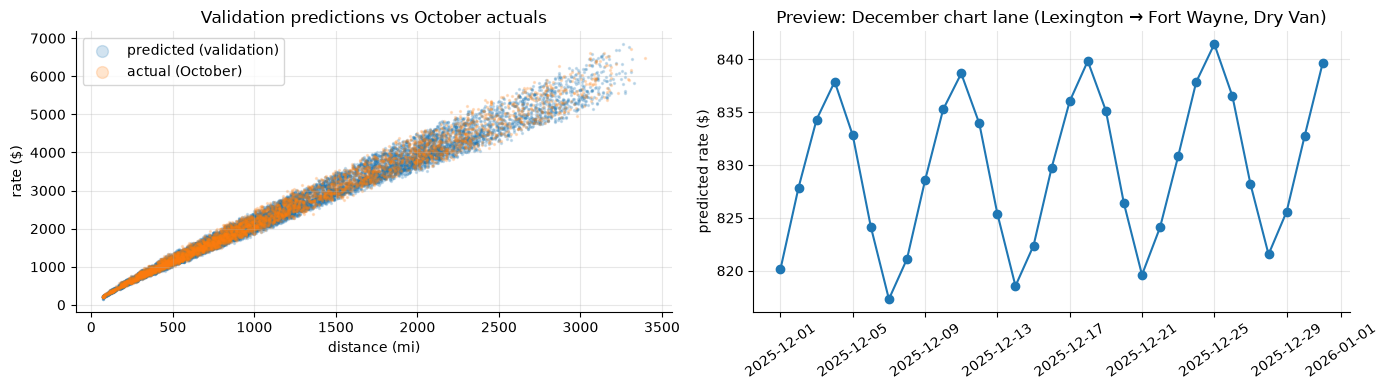

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(valid_clean.distance, pred_valid, s=2, alpha=0.2, label="predicted (validation)")
ax[0].scatter(train_clean.distance[train_clean.date.dt.month == 10], train_clean.posted_rate[train_clean.date.dt.month == 10],
              s=2, alpha=0.2, label="actual (October)")
ax[0].set_xlabel("distance (mi)"); ax[0].set_ylabel("rate ($)"); ax[0].legend(markerscale=6)
ax[0].set_title("Validation predictions vs October actuals")
ax[1].plot(december_clean.date, pred_dec, marker="o")
ax[1].set_title("Preview: December chart lane (Lexington → Fort Wayne, Dry Van)"); ax[1].set_ylabel("predicted rate ($)")
ax[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

## 5.5 Model summary

| Step | Choice | Why |
|---|---|---|
| Target | log(rate) | Effects act as percentages; predictions are always positive |
| Load-level structure | Ridge (19 engineered features) + LightGBM on its errors (6 features) | Best in 2 of 3 windows; trees fix Ridge's non-linear misses; LightGBM slightly ahead of scikit-learn's version in every window |
| Overall price level | Equal average of trend, market and persistence forecasts | Each single method fails in some window; averaging gives the lowest mean error without tuning weights |
| Not chosen | Neural network, PCA, recency weighting, `quote_signal` | Worse or unstable on the time windows; `quote_signal` is leakage |
| Expected error | See 5.4 output | Mean of three forecast windows; Spotter's score on Nov–Dec is the real test |

The biggest remaining risk is the Nov–Dec **price level**, which no feature in the data predicts reliably.

---
# 6. Final predictions & scoring

1. Fill the provided template's `predicted_rate` (same 12,000 `load_id`s, same order) → **`validation_predictions.csv`**
2. Fill the December chart inputs, keeping the original 7 columns and order → **`december-chart-predictions.csv`**
   (the provided `december-chart-inputs.csv` is left untouched)
3. Run the provided **`score.py`**, which validates both files and draws `scorer_results/candidate_december.png`

In [55]:
import subprocess
import sys
from IPython.display import Image, display

# 1. validation predictions, in the template's order
template = pd.read_csv(DATA_DIR / "validation-predictions-template.csv")
pred_by_id = pd.Series(pred_valid, index=valid_clean.load_id.to_numpy())
submission = template[["load_id"]].assign(predicted_rate=template.load_id.map(pred_by_id).round(2))
assert len(submission) == 12_000 and submission.predicted_rate.notna().all() and (submission.predicted_rate > 0).all()
assert list(submission.columns) == ["load_id", "predicted_rate"]
submission.to_csv("validation_predictions.csv", index=False)

# 2. December chart predictions, original file layout
dec_out = pd.read_csv(DATA_DIR / "december-chart-inputs.csv")
assert (pd.to_datetime(dec_out.date).to_numpy() == december_clean.date.to_numpy()).all()   # same rows, same order
dec_out["predicted_rate"] = np.round(pred_dec, 2)
dec_out.to_csv("december-chart-predictions.csv", index=False)

print(submission.head(3).to_string(index=False), "\n")
print(submission.predicted_rate.describe().round(2).to_string(), "\n")
print(dec_out.head(3).to_string(index=False))

  load_id  predicted_rate
TE-000001          855.50
TE-000002         5100.89
TE-000003         5175.04 

count    12000.00
mean      2355.45
std       1357.11
min        151.19
25%       1270.77
50%       2036.48
75%       3347.78
max       6845.55 

   pickup   delivery  distance equipment  weight       date  predicted_rate
Lexington Fort Wayne       360   Dry Van   32000 2025-12-01          820.14
Lexington Fort Wayne       360   Dry Van   32000 2025-12-02          827.86
Lexington Fort Wayne       360   Dry Van   32000 2025-12-03          834.30


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



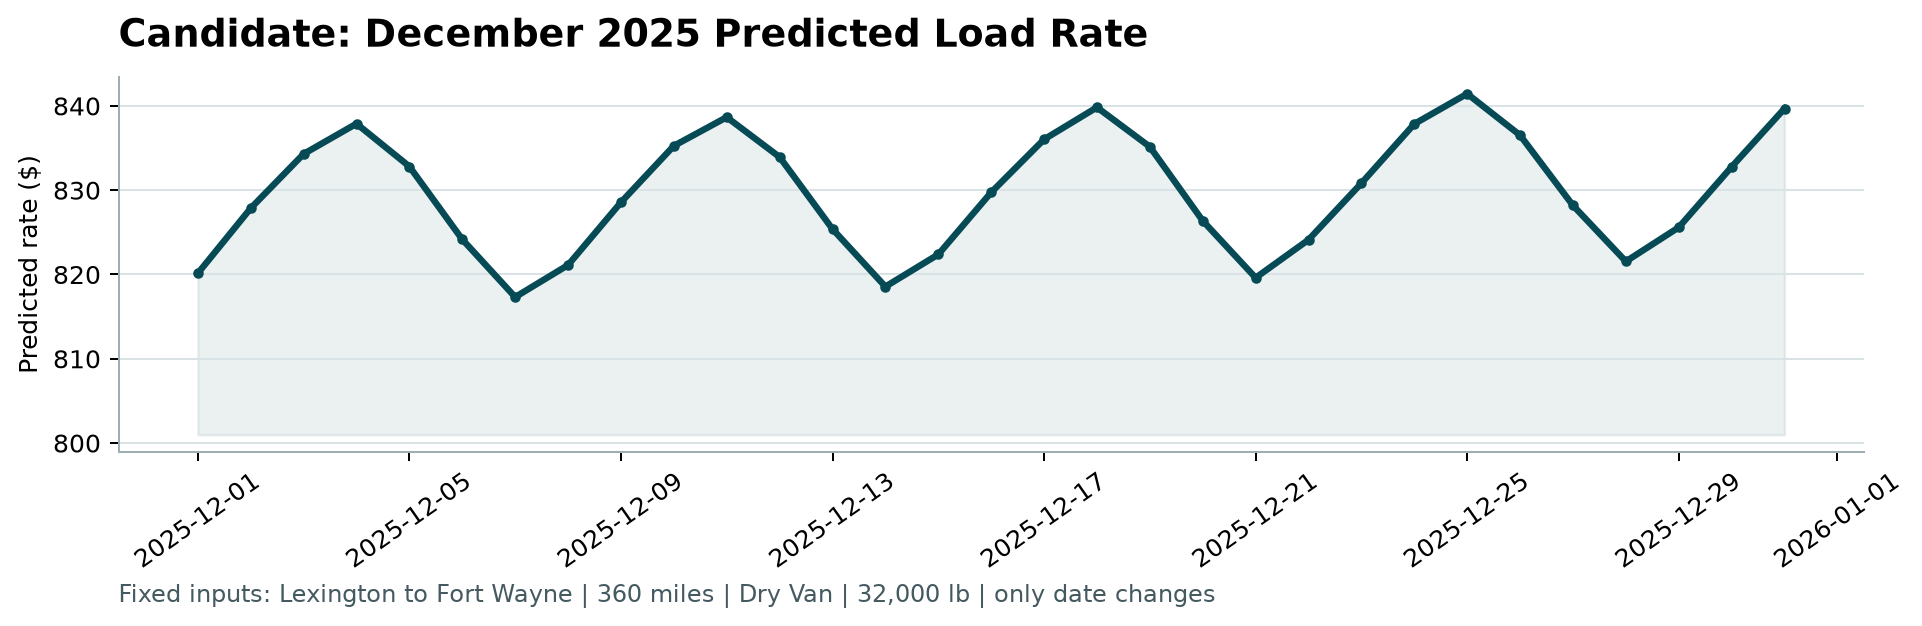

In [56]:
# 3. Run the provided scorer exactly as the README describes
result = subprocess.run([sys.executable, "score.py", "--predictions", "validation_predictions.csv",
                         "--december-predictions", "december-chart-predictions.csv"],
                        capture_output=True, text=True)
print(result.stdout or result.stderr)
assert result.returncode == 0, "score.py rejected the files"
display(Image("scorer_results/candidate_december.png"))

## 6.1 December chart: what drives its shape

All inputs are fixed except the date, so the line shows only the model's date effects:
- a **weekly cycle** (higher mid-week, lower at weekends) from `market_index`'s weekly pattern, which tracked rates all year (section 3.2);
- a **gentle drift** from the trend component of the price-level forecast (one third of the level average).

There is no holiday dip or spike around Christmas, because the training data shows no measurable holiday effects
(section 3) and contains no December.

In [57]:
chart = dec_out.assign(date=pd.to_datetime(dec_out.date), weekday=lambda d: d.date.dt.day_name())
by_day = chart.groupby("weekday").predicted_rate.mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print("mean predicted rate by weekday:", by_day.round(1).to_dict())
print(f"first week mean ${chart.predicted_rate[:7].mean():.1f} → last week mean ${chart.predicted_rate[-7:].mean():.1f}")
print(f"range ${chart.predicted_rate.min():.2f}–${chart.predicted_rate.max():.2f} "
      f"(±{100 * (chart.predicted_rate.max() - chart.predicted_rate.min()) / 2 / chart.predicted_rate.mean():.1f}%)")
lane_hist = train_clean[(train_clean.pickup == "Lexington") & (train_clean.delivery == "Fort Wayne") & (train_clean.equipment == "Dry Van")]
print(f"Lexington → Fort Wayne Dry Van in training: {len(lane_hist)} loads, median ${lane_hist.posted_rate.median():.0f} "
      f"(median distance {lane_hist.distance.median():.0f} mi)")

mean predicted rate by weekday: {'Monday': 822.7, 'Tuesday': 830.0, 'Wednesday': 836.6, 'Thursday': 839.5, 'Friday': 834.6, 'Saturday': 826.0, 'Sunday': 819.3}
first week mean $827.8 → last week mean $832.2
range $817.32–$841.44 (±1.5%)
Lexington → Fort Wayne Dry Van in training: 21 loads, median $808 (median distance 362 mi)


## 6.2 Deliverables produced by this notebook

| File | Contents |
|---|---|
| `validation_predictions.csv` | `load_id,predicted_rate` for all 12,000 validation loads |
| `december-chart-predictions.csv` | The 31 December chart inputs with `predicted_rate` filled |
| `scorer_results/candidate_december.png` | The fixed December chart from `score.py`, for the report |
| `data_clean/` | Cleaned data (regenerated on every run, not committed) |